# Практичне завдання 2: Логістична регресія та федеративне навчання

**Виконав:** Держко Захар, група ФеІ-45

**Датасет:** Dry Bean Dataset (Koklu & Ozkan, 2020) — 13 611 зерен квасолі 7 сортів, 16 числових геометричних ознак,
отриманих комп'ютерним зором із фотографій зерен.

**Зміст**
1. Етап 1 — EDA, відбір ознак, розбиття (Global Test / Global Validation / FL Train Pool), масштабування
2. Етап 2 — багатокласова логістична регресія (softmax) на numpy
3. Етап 3 — централізована базова модель: підбір гіперпараметрів, Ridge, метрики
4. Етап 4 — розподіл даних між клієнтами: IID та Non-IID (Діріхле)
5. Етап 5 — симуляція FedAvg
6. Етап 6 — локальні vs глобальна vs централізована моделі; Експеримент 1 (неоднорідність), Експеримент 2 (локальні епохи)
7. Етап 7 (опційно) — Експеримент А (кількість клієнтів) та Експеримент Б (персоналізація)
8. Два завдання з лекційного ноутбука: ділення на нуль при p = 1 та доведення Odds Ratio = e^w
9. Відповіді на теоретичні питання та загальний висновок

> Модель (softmax, втрати, градієнти, міні-батчевий GD), розподіл даних між клієнтами, федеративне масштабування
> та агрегація FedAvg реалізовані на `numpy`. `scikit-learn` використовується лише для стратифікованого розбиття,
> статистик відбору ознак та метрик; `LogisticRegression` — лише як допоміжна перевірка правильності реалізації.

In [1]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
np.random.seed(SEED)
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 30)

## Етап 1. Дослідження даних та попередня обробка

### 1.0 Обґрунтування вибору датасету

* **Багатокласова задача:** 7 сортів (`BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, SIRA`), тобто вимога «≥ 3 класи» виконана.
* **Достатній обсяг:** ~13.5 тис. прикладів — після виділення Test/Validation у FL Train Pool лишається ~9.5 тис., тож
  навіть при 10 клієнтах кожен має сотні прикладів.
* **Природний федеративний сценарій:** такі ознаки обчислюють системи машинного зору на лініях сортування зерна.
  Різні господарства/елеватори мають власні камери та дані, які є комерційною таємницею, і вирощують *різні сорти
  в різних пропорціях* — це і є реальна Non-IID неоднорідність, яку ми моделюємо розподілом Діріхле.
* **Дисбаланс класів** (DERMASON ≈ 26 %, BOMBAY ≈ 4 %) робить показовим порівняння accuracy з macro-F1 та balanced accuracy.
* Усі ознаки числові, без пропусків — фокус роботи на моделі й федеративній частині, а не на складній очистці.

### 1.1 Первинний аналіз

**Джерело даних.** Файл `Dry_Bean_Dataset.xlsx` завантажено з Kaggle
([muratkokludataset/dry-bean-dataset](https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset)); цей самий набір
опубліковано в UCI Machine Learning Repository. Автори: Murat Koklu, Ilker Ali Ozkan (Selcuk University, Туреччина).
Зерна 7 зареєстрованих сортів сфотографовано камерою високої роздільності; після сегментації зображень для кожного зерна
обчислено 16 ознак — 12 розмірних (площа, периметр, осі тощо) і 4 ознаки форми (ShapeFactor1–4).

*Цитування:* Koklu, M., Ozkan, I.A. (2020). Multiclass Classification of Dry Beans Using Computer Vision and Machine Learning
Techniques. *Computers and Electronics in Agriculture*, 174, 105507. https://doi.org/10.1016/j.compag.2020.105507

In [2]:
# Оригінальний файл з Kaggle: https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset
# (лежить поруч з ноутбуком; для читання .xlsx потрібен пакет openpyxl)
DATA_PATH = 'Dry_Bean_Dataset.xlsx'
df = pd.read_excel(DATA_PATH)

FEATURES_ALL = [c for c in df.columns if c != 'Class']
print('Розмір:', df.shape)
print('Типи ознак:', df[FEATURES_ALL].dtypes.value_counts().to_dict(), '| ціль Class:', df['Class'].dtype)
print('Пропущених значень:', int(df.isna().sum().sum()))
print('Повних дублікатів рядків:', int(df.duplicated().sum()))
df.head()

Розмір: (13611, 17)
Типи ознак: {dtype('float64'): 14, dtype('int64'): 2} | ціль Class: str
Пропущених значень: 0
Повних дублікатів рядків: 68


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


**Дублікати.** 68 рядків повністю повторюються. Якщо лишити їх, копія одного зерна може потрапити і в Train, і в Test —
це прихований витік даних (модель «бачила» тестовий приклад). Тому видаляємо дублікати **до** розбиття.

Після видалення дублікатів: (13543, 17) | класів: 7


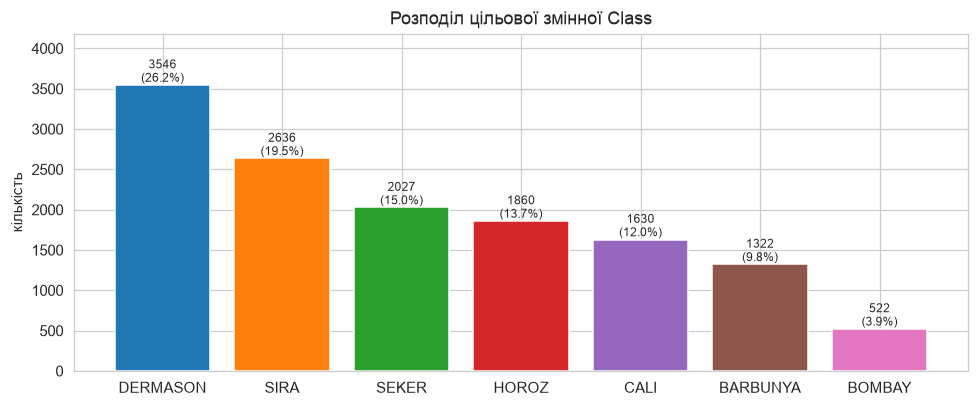

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
CLASSES = sorted(df['Class'].unique())
C = len(CLASSES)
cls2id = {c: i for i, c in enumerate(CLASSES)}
print('Після видалення дублікатів:', df.shape, '| класів:', C)

vc = df['Class'].value_counts()
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(vc.index, vc.values, color=sns.color_palette('tab10', C))
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 40, f'{v}\n({v / len(df):.1%})', ha='center', fontsize=8)
ax.set_title('Розподіл цільової змінної Class'); ax.set_ylabel('кількість'); ax.set_ylim(0, vc.max() * 1.18)
plt.tight_layout(); plt.show()

In [4]:
df[FEATURES_ALL].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
Area,13543.0,53048.460,29392.438,20420.000,36282.500,44580.000,61382.000,254616.000
Perimeter,13543.0,854.993,214.723,524.736,703.230,793.896,977.146,1985.370
MajorAxisLength,13543.0,319.896,85.809,183.601,253.087,296.405,376.312,738.860
MinorAxisLength,13543.0,202.365,45.052,122.513,175.886,192.491,217.245,460.198
AspectRation,13543.0,1.581,0.245,1.025,1.431,1.550,1.704,2.430
Eccentricity,13543.0,0.750,0.092,0.219,0.715,0.764,0.810,0.911
ConvexArea,13543.0,53767.987,29844.249,20684.000,36673.000,45122.000,62360.000,263261.000
EquivDiameter,13543.0,253.034,59.308,161.244,214.933,238.246,279.560,569.374
Extent,13543.0,0.750,0.049,0.555,0.719,0.760,0.787,0.866
Solidity,13543.0,0.987,0.005,0.919,0.986,0.988,0.990,0.995


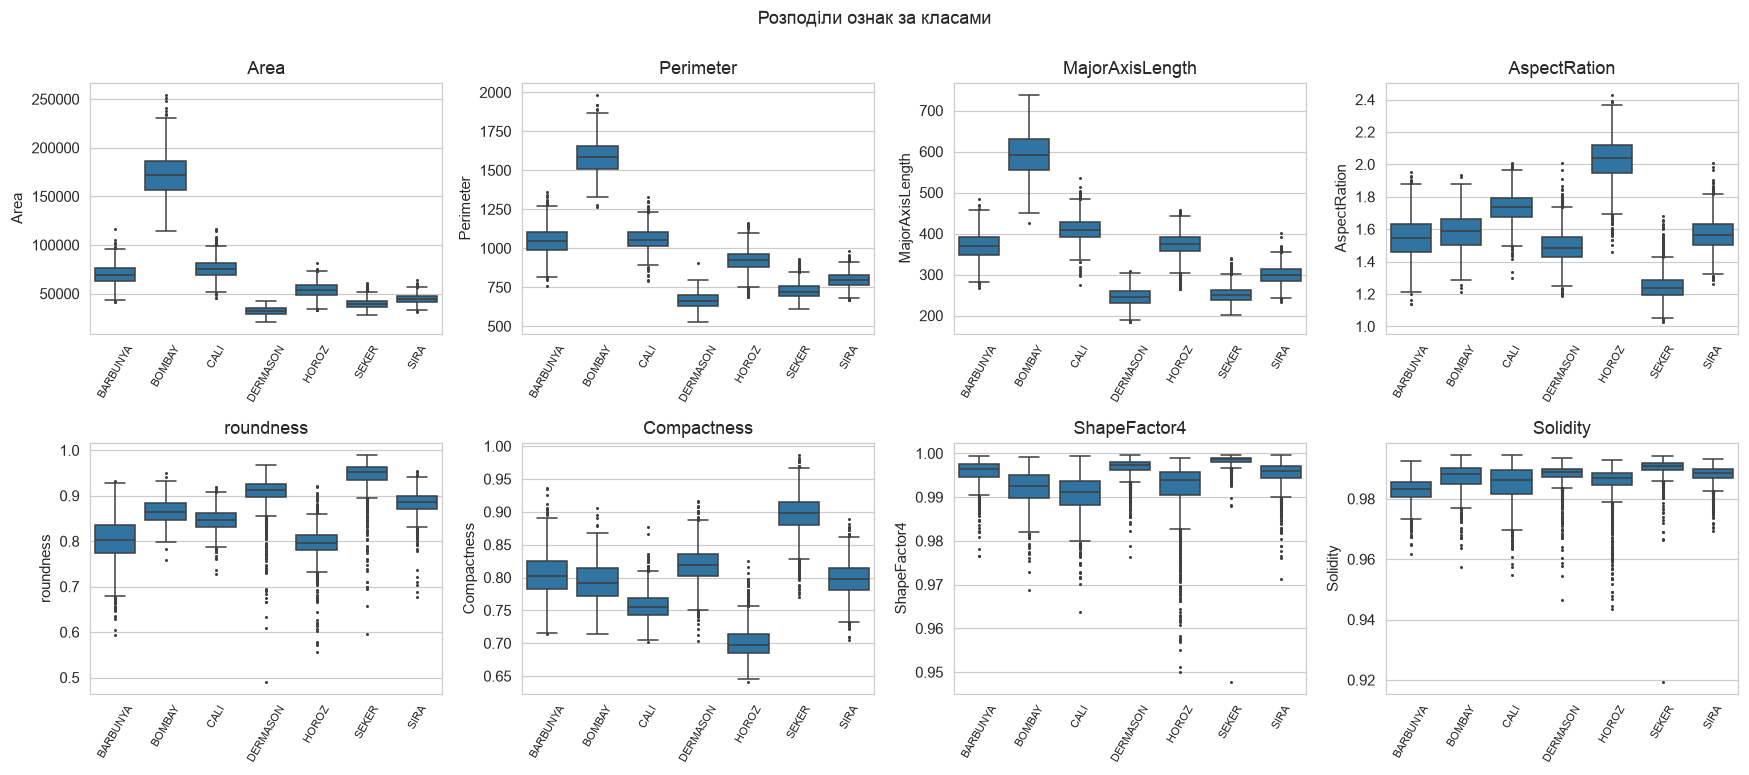

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.ravel(), ['Area', 'Perimeter', 'MajorAxisLength', 'AspectRation',
                                'roundness', 'Compactness', 'ShapeFactor4', 'Solidity']):
    sns.boxplot(data=df, x='Class', y=f, ax=ax, order=CLASSES, fliersize=1)
    ax.set_title(f); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=60, labelsize=7)
plt.suptitle('Розподіли ознак за класами', y=1.0); plt.tight_layout(); plt.show()

**Спостереження.** Ознаки мають дуже різні масштаби (`Area` — десятки тисяч пікселів, `ShapeFactor2` — тисячні частки),
тож без стандартизації градієнтний спуск працював би погано (див. Практичне 1). Класи добре розрізняються за розміром
(BOMBAY — найбільші зерна, DERMASON — найменші) і формою (HOROZ — видовжені, SEKER — круглі), тому можна очікувати, що
навіть лінійна модель досягне високої точності.

### 1.2 Розбиття вибірки: Global Test (15 %) / Global Validation (15 %) / FL Train Pool (70 %)

Розбиття стратифіковане за класами і виконується **першим**, до відбору ознак та масштабування.

* **Global Test** — зберігається на сервері, використовується *один раз* для фінальної оцінки.
* **Global Validation** — на сервері, для підбору гіперпараметрів і моніторингу раундів FL; клієнтам не передається.
* **FL Train Pool** — єдина частина, яку отримують клієнти.

**Питання: чому розбивати треба до масштабування/кодування? Що таке Data Leakage?**
*Data leakage* — потрапляння в процес навчання інформації, якої модель не мала б у момент реального прогнозу, насамперед
інформації з валідаційних/тестових даних. Масштабування, кодування, відбір ознак — це теж «навчання» (вони оцінюють
параметри: середні, дисперсії, списки категорій, кореляції). Якщо оцінити їх на всьому датасеті, у них потрапить інформація
про розподіл тестових об'єктів, і оцінка якості стане завищеною: модель протестована не на по-справжньому нових даних.
Тому спочатку розбиваємо, потім кожне перетворення робить `fit` лише на тренувальній частині й `transform` на решті.
У федеративному сценарії є додатковий аспект: витоком є також будь-яке використання Global Test/Validation клієнтами.

In [6]:
idx_all = np.arange(len(df))
y_all = df['Class'].map(cls2id).to_numpy()
idx_tmp, idx_test = train_test_split(idx_all, test_size=0.15, stratify=y_all, random_state=SEED)
idx_pool, idx_val = train_test_split(idx_tmp, test_size=0.15 / 0.85, stratify=y_all[idx_tmp], random_state=SEED)

pool_df, val_df, test_df = df.iloc[idx_pool], df.iloc[idx_val], df.iloc[idx_test]
split_tab = pd.DataFrame({
    'FL Train Pool': pool_df['Class'].value_counts(normalize=True),
    'Global Validation': val_df['Class'].value_counts(normalize=True),
    'Global Test': test_df['Class'].value_counts(normalize=True)}).loc[CLASSES].round(3)
split_tab.loc['— кількість'] = [len(pool_df), len(val_df), len(test_df)]
split_tab

,FL Train Pool,Global Validation,Global Test
Class,,,
BARBUNYA,0.098,0.097,0.097
BOMBAY,0.039,0.038,0.038
CALI,0.120,0.121,0.121
DERMASON,0.262,0.262,0.262
HOROZ,0.137,0.137,0.137
SEKER,0.150,0.150,0.150
SIRA,0.195,0.195,0.195
— кількість,9479.000,2032.000,2032.000


### 1.3 Відбір ознак (лише на FL Train Pool)

Ціль — категоріальна, тому замість кореляції Пірсона з ціллю використовуємо дві міри зв'язку «числова ознака ↔ клас»:
* **ANOVA F-статистика** — наскільки середні ознаки відрізняються між класами порівняно з розкидом усередині класів;
* **Mutual Information** — будь-яка (зокрема нелінійна) залежність.

Далі перевіряємо кореляції між самими ознаками: багато з них — різні формули з тих самих вимірів
(площа, периметр, осі еліпса), тож очікуємо сильну мультиколінеарність.

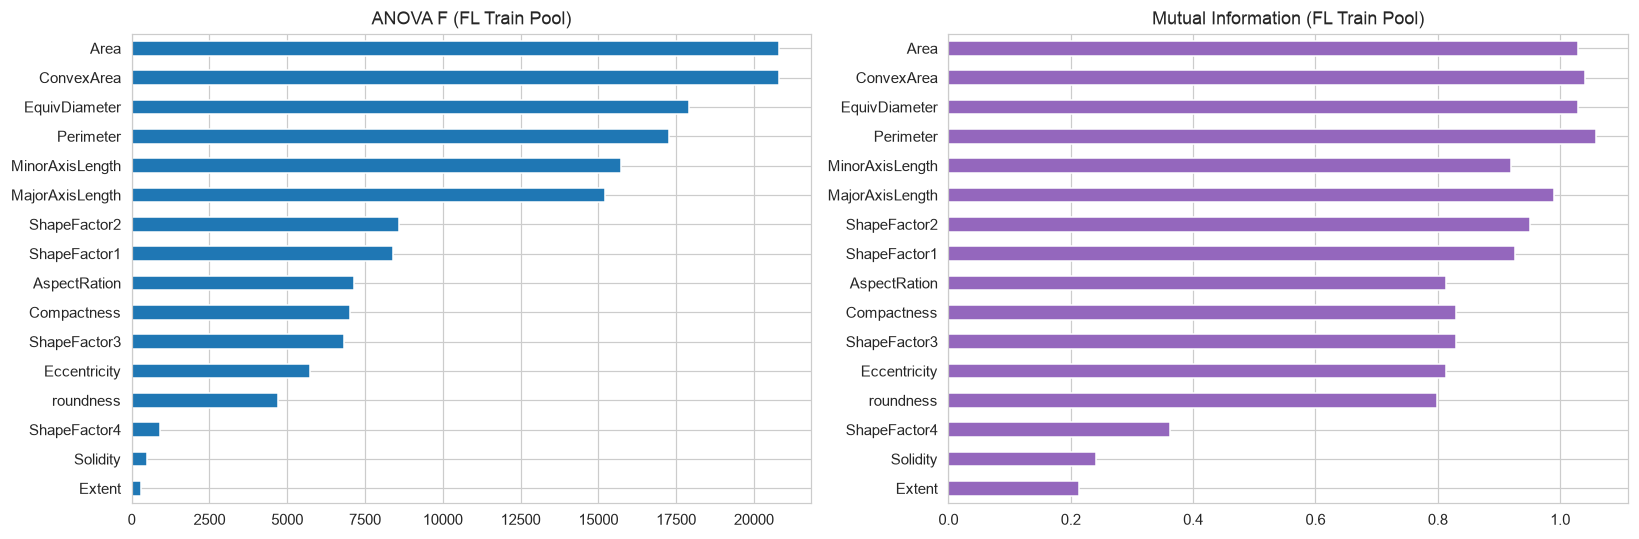

,ANOVA F,Mutual Info
Area,20803.065,1.030
ConvexArea,20792.553,1.040
EquivDiameter,17921.932,1.030
Perimeter,17270.926,1.058
MinorAxisLength,15742.467,0.920
MajorAxisLength,15210.152,0.991
ShapeFactor2,8578.794,0.951
ShapeFactor1,8393.849,0.926
AspectRation,7157.869,0.814
Compactness,7018.198,0.830


In [7]:
F_stat, _ = f_classif(pool_df[FEATURES_ALL], pool_df['Class'])
mi = mutual_info_classif(pool_df[FEATURES_ALL], pool_df['Class'], random_state=SEED)
rel = pd.DataFrame({'ANOVA F': F_stat, 'Mutual Info': mi}, index=FEATURES_ALL).sort_values('ANOVA F', ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
rel['ANOVA F'].iloc[::-1].plot(kind='barh', ax=ax[0], color='tab:blue'); ax[0].set_title('ANOVA F (FL Train Pool)')
rel['Mutual Info'].iloc[::-1].plot(kind='barh', ax=ax[1], color='tab:purple'); ax[1].set_title('Mutual Information (FL Train Pool)')
plt.tight_layout(); plt.show()
rel.round(3)

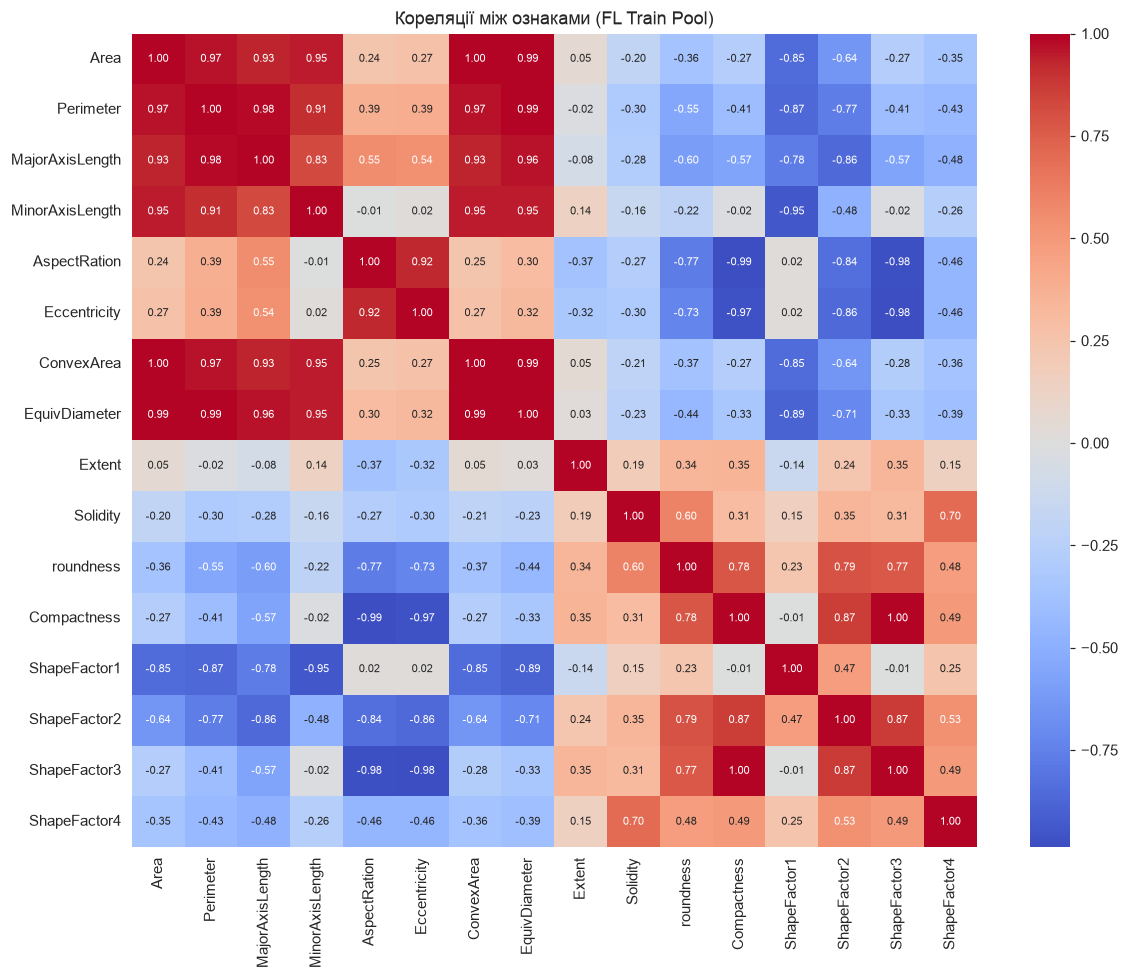

Пар ознак з |r| >= 0.95: 15
  Area             ConvexArea       r = +1.000
  Compactness      ShapeFactor3     r = +0.999
  Perimeter        EquivDiameter    r = +0.992
  AspectRation     Compactness      r = -0.988
  ConvexArea       EquivDiameter    r = +0.985
  Area             EquivDiameter    r = +0.985
  Eccentricity     ShapeFactor3     r = -0.981
  AspectRation     ShapeFactor3     r = -0.978
  Perimeter        MajorAxisLength  r = +0.978
  Eccentricity     Compactness      r = -0.970
  Perimeter        ConvexArea       r = +0.968
  Area             Perimeter        r = +0.967


In [8]:
corr = pool_df[FEATURES_ALL].corr()
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 7})
plt.title('Кореляції між ознаками (FL Train Pool)'); plt.tight_layout(); plt.show()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(FEATURES_ALL) for b in FEATURES_ALL[i + 1:] if abs(corr.loc[a, b]) >= 0.95]
print(f'Пар ознак з |r| >= 0.95: {len(pairs)}')
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2]))[:12]:
    print(f'  {a:16s} {b:16s} r = {r:+.3f}')

**Процедура відбору.** Проходимо ознаки за спаданням ANOVA F і додаємо ознаку, лише якщо її $|r|$ з усіма вже
відібраними $< 0.95$. Так із групи майже дублікатів (напр. `Area`, `ConvexArea`, `EquivDiameter`, `Perimeter` з $r>0.98$)
лишається одна — найінформативніша.

In [9]:
CORR_MAX = 0.95
FEATURES, dropped = [], []
for f in rel.index:
    clash = [s for s in FEATURES if abs(corr.loc[f, s]) >= CORR_MAX]
    if clash: dropped.append((f, clash[0], round(corr.loc[f, clash[0]], 3)))
    else: FEATURES.append(f)
print('Відібрані ознаки (%d):' % len(FEATURES), FEATURES)
print('\nВідкинуті (ознака, дублює, r):')
for t in dropped: print('  ', t)

Відібрані ознаки (10): ['Area', 'MajorAxisLength', 'ShapeFactor2', 'ShapeFactor1', 'AspectRation', 'Eccentricity', 'roundness', 'ShapeFactor4', 'Solidity', 'Extent']

Відкинуті (ознака, дублює, r):
   ('ConvexArea', 'Area', np.float64(1.0))
   ('EquivDiameter', 'Area', np.float64(0.985))
   ('Perimeter', 'Area', np.float64(0.967))
   ('MinorAxisLength', 'Area', np.float64(0.952))
   ('Compactness', 'AspectRation', np.float64(-0.988))
   ('ShapeFactor3', 'AspectRation', np.float64(-0.978))


Модель з 10 ознак замість 16 простіша й краще обумовлена. Чи не втрачаємо ми якість — перевіримо на Global Validation
в Етапі 3 (порівняння «всі 16» vs «10 відібраних»).

### 1.4 Кодування категоріальних ознак

Усі 16 ознак — числові, тож кодування ознак **не потрібне**. Кодуємо лише ціль: мітки `Class` → індекси `0..6` за фіксованим
алфавітним списком класів, а для функції втрат — **one-hot** матриця $Y \in \{0,1\}^{m\times C}$. One-Hot, а не ordinal,
бо сорти не мають порядку; Target Encoding до цілі не застосовується за визначенням.
(Якби в даних були категоріальні ознаки, вибір між One-Hot/Ordinal/Target Encoding обґрунтовувався б так само, як
у Практичному 1: One-Hot для невпорядкованих категорій з невеликою кардинальністю, Ordinal — для впорядкованих,
Target Encoding — для високої кардинальності, лише з out-of-fold схемою, щоб уникнути витоку.)

In [10]:
X_pool_raw = pool_df[FEATURES].to_numpy(float); y_pool = pool_df['Class'].map(cls2id).to_numpy()
X_val_raw = val_df[FEATURES].to_numpy(float);   y_val = val_df['Class'].map(cls2id).to_numpy()
X_test_raw = test_df[FEATURES].to_numpy(float); y_test = test_df['Class'].map(cls2id).to_numpy()

def one_hot(y, C=C):
    Y = np.zeros((len(y), C)); Y[np.arange(len(y)), y] = 1.0
    return Y
print(one_hot(y_pool[:3]), '<- one-hot для перших трьох прикладів, класи:', [CLASSES[i] for i in y_pool[:3]])

[[0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 1.]] <- one-hot для перших трьох прикладів, класи: ['BOMBAY', 'SEKER', 'SIRA']


### 1.5 Масштабування — федеративний варіант (б)

Використовуємо **підхід (б)**: жоден учасник не бачить чужих сирих даних.
1. Кожен клієнт $k$ обчислює на своїх даних лише три агрегати: $n_k$, $\mu_k$ (вектор середніх), $\sigma_k^2$ (вектор дисперсій).
2. Сервер агрегує їх зважено за кількістю прикладів:
$$\mu = \frac{1}{N}\sum_k n_k\mu_k,\qquad \sigma^2 = \frac{1}{N}\sum_k n_k\left(\sigma_k^2 + \mu_k^2\right) - \mu^2,\qquad N=\sum_k n_k .$$
   (Друга формула — це $\mathrm{Var}(x) = \mathbb{E}[x^2] - (\mathbb{E}x)^2$, де $\mathbb{E}[x^2]$ кожного клієнта $= \sigma_k^2+\mu_k^2$.)
3. Сервер розсилає $(\mu, \sigma)$ клієнтам і сам застосовує їх до Global Validation і Global Test.
   Test/Validation у обчисленні статистик участі **не беруть**.

Оскільки суми $\sum x$ і $\sum x^2$ адитивні, результат *точно* збігається зі статистиками всього FL Train Pool — тобто
з підходом (а), але без передачі сирих даних. Це перевіряємо нижче. Функції розподілу даних між клієнтами визначено в
Етапі 4; тут для обчислення скалера використано IID-розподіл на 5 клієнтів (для будь-якого іншого розподілу результат той самий,
що теж перевірено).

In [11]:
def client_stats(X_local):
    # Клієнт повертає серверу ЛИШЕ агрегати, а не дані
    return len(X_local), X_local.mean(0), X_local.var(0)

def server_aggregate_stats(stats):
    n = np.array([s[0] for s in stats], float)
    mu_k = np.stack([s[1] for s in stats]); var_k = np.stack([s[2] for s in stats])
    N = n.sum()
    mu = (n[:, None] * mu_k).sum(0) / N
    var = (n[:, None] * (var_k + mu_k ** 2)).sum(0) / N - mu ** 2
    return mu, np.sqrt(var)

Чому обраний датасет підходить для федеративного навчання:
Датасет Dry Bean Dataset є чудовим вибором для симуляції федеративного навчання (FL).
Багатокласовість: Ми маємо 7 класів (сортів квасолі), що відповідає вимогам завдання.
Обсяг даних: Понад 13 000 екземплярів достатньо для того, щоб розділити їх між кількома клієнтами так, щоб кожен мав репрезентативну вибірку.
Сценарій використання: Дані містять фізичні характеристики зерен, отримані за допомогою комп'ютерного зору. Можна уявити реальний сценарій: різні аграрні підприємства (клієнти) використовують свої камери для аналізу різних сортів квасолі. З міркувань комерційної таємниці вони не хочуть ділитися сирими даними, але можуть спільно навчати глобальну модель.

Data Leakage (Витік даних)
Термін Data Leakage означає ситуацію, коли інформація з тестової або валідаційної вибірки неявно потрапляє до моделі під час її навчання.
Наприклад, якщо ми застосуємо StandardScaler до всього датасету до його розбиття, середнє значення та дисперсія будуть розраховані з урахуванням тестових даних. Це дасть моделі "підказку" про розподіл тестової вибірки, що призведе до завищених і нереалістичних оцінок її продуктивності.
Тому розбиття даних (на FL Train Pool, Global Validation та Global Test) обов'язково має виконуватися перед будь-яким масштабуванням.

## Етап 2. Багатокласова логістична регресія (softmax) на numpy

$$Z = XW + b,\qquad P = \mathrm{softmax}(Z),\qquad P_{ic} = \frac{e^{Z_{ic}}}{\sum_{j=1}^{C} e^{Z_{ij}}} .$$

**Числова стабільність.** $e^{Z}$ переповнюється вже при $Z\approx 710$. Оскільки softmax не змінюється від додавання
константи до всіх логітів рядка ($\frac{e^{Z_{ic}-a}}{\sum_j e^{Z_{ij}-a}} = \frac{e^{Z_{ic}}}{\sum_j e^{Z_{ij}}}$), віднімаємо
максимум рядка: найбільший показник стає 0, переповнення неможливе.

**Функція втрат** (крос-ентропія + Ridge):
$$J(W,b) = -\frac1m\sum_{i=1}^{m}\sum_{c=1}^{C} Y_{ic}\log P_{ic} + \frac{\lambda}{2}\lVert W\rVert_F^2 .$$
Під логарифм підставляємо $\max(P_{ic}, 10^{-15})$, щоб уникнути $\log 0$.

**Градієнти:**
$$\frac{\partial J}{\partial W} = \frac1m X^\top(P - Y) + \lambda W,\qquad \frac{\partial J}{\partial b} = \frac1m \mathbf 1_m^\top(P - Y).$$

*Звідки $P-Y$:* для одного прикладу $\partial(-\sum_c Y_c\log P_c)/\partial Z_j = P_j - Y_j$ (похідна softmax
$\partial P_c/\partial Z_j = P_c(\delta_{cj}-P_j)$ скорочується з $1/P_c$ від логарифма, а $\sum_c Y_c = 1$). Далі
$Z = XW+b$ дає множник $X^\top$ для $W$ та суму по прикладах для $b$.

Зсув $b$ не регуляризуємо. Цикли `for` у втратах і градієнтах відсутні; цикли є лише по епохах і батчах.

In [12]:
class SoftmaxRegression:
    # Багатокласова логістична регресія: P = softmax(XW + b), навчання міні-батчевим GD

    def __init__(self, d, C, lam=0.0, seed=SEED):
        self.d, self.C, self.lam = d, C, lam
        self.W = np.zeros((d, C))
        self.b = np.zeros((1, C))
        self.rng = np.random.default_rng(seed)

    # ---------- параметри (для обміну в FL) ----------
    def get_params(self):
        return {'W': self.W.copy(), 'b': self.b.copy()}

    def set_params(self, params):
        self.W, self.b = params['W'].copy(), params['b'].copy()

    # ---------- модель ----------
    @staticmethod
    def softmax(Z):
        Z = Z - Z.max(axis=1, keepdims=True)          # стабільність: віднімаємо максимум рядка
        E = np.exp(Z)
        return E / E.sum(axis=1, keepdims=True)

    def predict_proba(self, X):
        return self.softmax(X @ self.W + self.b)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def loss(self, X, Y):
        P = self.predict_proba(X)
        ce = -np.sum(Y * np.log(np.clip(P, 1e-15, 1.0))) / len(X)
        return ce + self.lam / 2 * np.sum(self.W ** 2)

    def gradients(self, X, Y):
        m = len(X)
        G = self.predict_proba(X) - Y                  # (m, C) = P - Y
        dW = X.T @ G / m + self.lam * self.W
        db = G.sum(axis=0, keepdims=True) / m          # = 1^T (P - Y) / m
        return dW, db

    def update(self, dW, db, lr):
        self.W -= lr * dW
        self.b -= lr * db

    # ---------- навчання ----------
    def fit(self, X, y, epochs=50, batch_size=64, lr=0.1, X_val=None, y_val=None, record=True):
        Y = one_hot(y, self.C)
        Yv = one_hot(y_val, self.C) if X_val is not None else None
        hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
        m = len(X)
        for epoch in range(epochs):
            perm = self.rng.permutation(m)
            for s in range(0, m, batch_size):
                bi = perm[s:s + batch_size]
                dW, db = self.gradients(X[bi], Y[bi])
                self.update(dW, db, lr)
            if record:
                hist['train_loss'].append(self.loss(X, Y)); hist['train_acc'].append((self.predict(X) == y).mean())
                if X_val is not None:
                    hist['val_loss'].append(self.loss(X_val, Yv)); hist['val_acc'].append((self.predict(X_val) == y_val).mean())
        self.history = hist
        return self


def evaluate(model, X, y):
    # Метрики для багатокласової класифікації
    P = model.predict_proba(X); pred = P.argmax(1)
    return {'accuracy': accuracy_score(y, pred),
            'macro-F1': f1_score(y, pred, average='macro'),
            'balanced acc': balanced_accuracy_score(y, pred),
            'log-loss': log_loss(y, P, labels=np.arange(C))}

Модель реалізована з використанням функції softmax для конвертації лінійних комбінацій Z = XW + b у вектор ймовірностей для кожного класу.Чому softmax? Softmax гарантує, що сума ймовірностей для всіх класів дорівнює 1, а кожне значення лежить у діапазоні (0, 1), що є природним для задач класифікації.Функція втрат: Використовується перехресна ентропія (Cross-Entropy). Вона є природною для логістичної регресії, оскільки максимізує логарифмічну правдоподібність (log-likelihood) правильних класів.Для стабілізації обчислень (уникнення переповнення при обчисленні експоненти) у функції softmax реалізовано віднімання максимального значення по кожному рядку.

### 2.1 Перевірки реалізації

1. **Стабільність softmax** на величезних логітах.
2. **Чисельна перевірка градієнта** (центральна різниця) для $W$ і $b$ з увімкненою регуляризацією.
3. **Допоміжне порівняння з `sklearn.LogisticRegression`** (дозволено умовою лише як орієнтир): при тому самому
   штрафі ($C_{sk} = 1/(\lambda m)$, multinomial) обидві реалізації мінімізують ту саму функцію. Перевіряємо, що
   значення $J$ збігаються і що *наш* градієнт у точці оптимуму sklearn дорівнює нулю. Тут використано тимчасовий
   скалер, оцінений на FL Train Pool — лише для перевірки коду; основні результати від цього не залежать.

In [13]:
Z_big = np.array([[1000., 1001., 1002.], [-1000., 0., 1000.]])
print('softmax на логітах ±1000:\n', SoftmaxRegression.softmax(Z_big).round(4))

rng = np.random.default_rng(0)
_mu, _sd = X_pool_raw.mean(0), X_pool_raw.std(0)
Xc = (X_pool_raw[:300] - _mu) / _sd; Yc = one_hot(y_pool[:300])
m_chk = SoftmaxRegression(len(FEATURES), C, lam=0.05)
m_chk.W = rng.normal(size=m_chk.W.shape) * 0.5; m_chk.b = rng.normal(size=m_chk.b.shape) * 0.5
dW, db = m_chk.gradients(Xc, Yc)
eps = 1e-6; num_dW = np.zeros_like(dW); num_db = np.zeros_like(db)
for i in range(dW.shape[0]):          # цикл лише в тесті
    for j in range(C):
        m_chk.W[i, j] += eps; lp = m_chk.loss(Xc, Yc); m_chk.W[i, j] -= 2 * eps; lm = m_chk.loss(Xc, Yc); m_chk.W[i, j] += eps
        num_dW[i, j] = (lp - lm) / (2 * eps)
for j in range(C):
    m_chk.b[0, j] += eps; lp = m_chk.loss(Xc, Yc); m_chk.b[0, j] -= 2 * eps; lm = m_chk.loss(Xc, Yc); m_chk.b[0, j] += eps
    num_db[0, j] = (lp - lm) / (2 * eps)
print('Відносна похибка dW:', np.abs(num_dW - dW).max() / np.abs(dW).max())
print('Відносна похибка db:', np.abs(num_db - db).max() / np.abs(db).max())

softmax на логітах ±1000:
 [[0.09   0.2447 0.6652]
 [0.     0.     1.    ]]
Відносна похибка dW: 1.3859932876671615e-09
Відносна похибка db: 1.1809490031313776e-09


In [14]:
from sklearn.linear_model import LogisticRegression   # ЛИШЕ для допоміжної перевірки
Xs = (X_pool_raw - _mu) / _sd; Ys = one_hot(y_pool)
lam_chk = 1e-3
ours = SoftmaxRegression(len(FEATURES), C, lam=lam_chk).fit(Xs, y_pool, epochs=300, batch_size=64, lr=0.1, record=False)
# sklearn мінімізує  sum(CE) + ||W||^2 / (2C)  =  m * [ mean(CE) + λ/2 ||W||^2 ]  при  C = 1/(λ m)
sk = LogisticRegression(C=1 / (lam_chk * len(Xs)), max_iter=5000, tol=1e-10).fit(Xs, y_pool)
sk_as_ours = SoftmaxRegression(len(FEATURES), C, lam=lam_chk)
sk_as_ours.W, sk_as_ours.b = sk.coef_.T.copy(), sk.intercept_[None, :].copy()
dW_sk, db_sk = sk_as_ours.gradients(Xs, Ys)
print(f'J(наша модель після GD)      = {ours.loss(Xs, Ys):.5f}')
print(f'J(параметри sklearn, оптимум) = {sk_as_ours.loss(Xs, Ys):.5f}')
print(f'‖наш градієнт‖ у точці оптимуму sklearn: dW = {np.linalg.norm(dW_sk):.1e}, db = {np.linalg.norm(db_sk):.1e}  (≈ 0 → формули градієнта правильні)')
print('Макс. різниця ймовірностей:', np.abs(ours.predict_proba(Xs) - sk.predict_proba(Xs)).max().round(4))
print('Збіг передбачених класів:', (ours.predict(Xs) == sk.predict(Xs)).mean().round(4))

J(наша модель після GD)      = 0.28032
J(параметри sklearn, оптимум) = 0.28010
‖наш градієнт‖ у точці оптимуму sklearn: dW = 5.0e-08, db = 2.1e-08  (≈ 0 → формули градієнта правильні)
Макс. різниця ймовірностей: 0.1049
Збіг передбачених класів: 0.9978


## Етап 4 (частково). Функції розподілу даних між клієнтами

Функції розподілу потрібні вже для федеративного скалера, тому визначаємо їх тут; візуалізація та аналіз — в Етапі 4.

* **IID:** стратифіковано ділимо кожен клас на $K$ майже рівних частин — у всіх клієнтів однакові розміри та пропорції класів.
* **Non-IID (Діріхле):** для кожного класу $c$ генеруємо $(p_{1c},\dots,p_{Kc})\sim\mathrm{Dir}(\alpha,\dots,\alpha)$ і ділимо
  приклади цього класу між клієнтами у цих пропорціях. Якщо хоч один клієнт отримав менше `min_size` прикладів,
  генеруємо розподіл заново (з тим самим генератором — результат відтворюваний).

Кожен приклад потрапляє рівно до одного клієнта (перевіряється `assert`).

In [15]:
def iid_partition(y, K, seed=SEED):
    rng = np.random.default_rng(seed)
    parts = [[] for _ in range(K)]
    for c in np.unique(y):
        idx = rng.permutation(np.where(y == c)[0])
        offset = rng.integers(K)                              # щоб «зайві» приклади не завжди йшли клієнту 0
        for j, chunk in enumerate(np.array_split(idx, K)):
            parts[(j + offset) % K].extend(chunk.tolist())
    return [np.sort(np.array(p)) for p in parts]

def dirichlet_partition(y, K, alpha, seed=SEED, min_size=10, max_tries=1000):
    rng = np.random.default_rng(seed)
    for attempt in range(1, max_tries + 1):
        parts = [[] for _ in range(K)]
        for c in np.unique(y):
            idx = rng.permutation(np.where(y == c)[0])
            p = rng.dirichlet(alpha * np.ones(K))
            cuts = (np.cumsum(p)[:-1] * len(idx)).astype(int)
            for k, chunk in enumerate(np.split(idx, cuts)):
                parts[k].extend(chunk.tolist())
        if min(len(p) for p in parts) >= min_size:
            break
    parts = [np.sort(np.array(p)) for p in parts]
    parts_attempts = attempt
    return parts, parts_attempts

def check_partition(parts, n_total):
    allidx = np.concatenate(parts)
    assert len(allidx) == n_total and len(np.unique(allidx)) == n_total, 'кожен приклад має належати рівно одному клієнту'
    return True

In [16]:
parts_iid5 = iid_partition(y_pool, K=5)
check_partition(parts_iid5, len(y_pool))

# Федеративне обчислення скалера: клієнти -> агрегати -> сервер
stats = [client_stats(X_pool_raw[p]) for p in parts_iid5]
MU, SIGMA = server_aggregate_stats(stats)

print('Макс. |μ_fed − μ_pool| =', np.abs(MU - X_pool_raw.mean(0)).max())
print('Макс. |σ_fed − σ_pool| / σ =', (np.abs(SIGMA - X_pool_raw.std(0)) / X_pool_raw.std(0)).max())
parts_chk, _ = dirichlet_partition(y_pool, 5, alpha=0.3)
MU2, SIG2 = server_aggregate_stats([client_stats(X_pool_raw[p]) for p in parts_chk])
print('Для Non-IID розподілу (α=0.3) статистики ті самі:', np.allclose(MU, MU2), np.allclose(SIGMA, SIG2))

scale = lambda X: (X - MU) / SIGMA
X_pool, X_val, X_test = scale(X_pool_raw), scale(X_val_raw), scale(X_test_raw)
print('\nСередні Global Test після масштабування (не рівно 0, як і має бути):', X_test.mean(0).round(3))

Макс. |μ_fed − μ_pool| = 1.1368683772161603e-13
Макс. |σ_fed − σ_pool| / σ = 7.247390153402955e-12
Для Non-IID розподілу (α=0.3) статистики ті самі: True True

Середні Global Test після масштабування (не рівно 0, як і має бути): [ 0.004  0.009 -0.013 -0.013  0.007  0.012 -0.022  0.031  0.008 -0.012]


Масштабування застосовується до FL Train Pool один раз, а потім розбиваємо *індекси* між клієнтами.
Це еквівалентно тому, що кожен клієнт отримав $(\mu,\sigma)$ від сервера і масштабував свої дані сам.

## Етап 3. Централізована базова модель

Навчання на всьому FL Train Pool. Гіперпараметри обираємо за **log-loss на Global Validation**
(log-loss чутливіший за accuracy і оцінює якість ймовірностей). Global Test не використовується.

### 3.1 Learning rate та розмір батчу (λ = 0)

In [17]:
EPOCHS_C = 60
lr_grid, bs_grid = [0.01, 0.03, 0.1, 0.3, 1.0], [32, 128, 512]
rows, curves = [], {}
for bs in bs_grid:
    for lr in lr_grid:
        t0 = time.perf_counter()
        mdl = SoftmaxRegression(len(FEATURES), C).fit(X_pool, y_pool, EPOCHS_C, bs, lr, X_val, y_val)
        curves[(lr, bs)] = mdl.history
        rows.append({'lr': lr, 'batch': bs, 'val log-loss': mdl.history['val_loss'][-1],
                     'val acc': mdl.history['val_acc'][-1], 'час, с': time.perf_counter() - t0})
grid = pd.DataFrame(rows)
display(grid.pivot(index='lr', columns='batch', values='val log-loss').round(4))
display(grid.pivot(index='lr', columns='batch', values='val acc').round(4))
best_row = grid.sort_values('val log-loss').iloc[0]
LR, BS = float(best_row['lr']), int(best_row['batch'])
print(f'Найкраще: lr = {LR}, batch = {BS}')

batch,32,128,512
lr,,,
0.01,0.2859,0.3911,0.6446
0.03,0.2545,0.2991,0.4275
0.10,0.2397,0.2583,0.3085
0.30,0.2346,0.2422,0.2646
1.00,0.2347,0.2352,0.2436


batch,32,128,512
lr,,,
0.01,0.9198,0.9065,0.8563
0.03,0.9203,0.9163,0.9035
0.10,0.9227,0.9208,0.9158
0.30,0.9227,0.9222,0.9208
1.00,0.9247,0.9232,0.9222


Найкраще: lr = 0.3, batch = 32


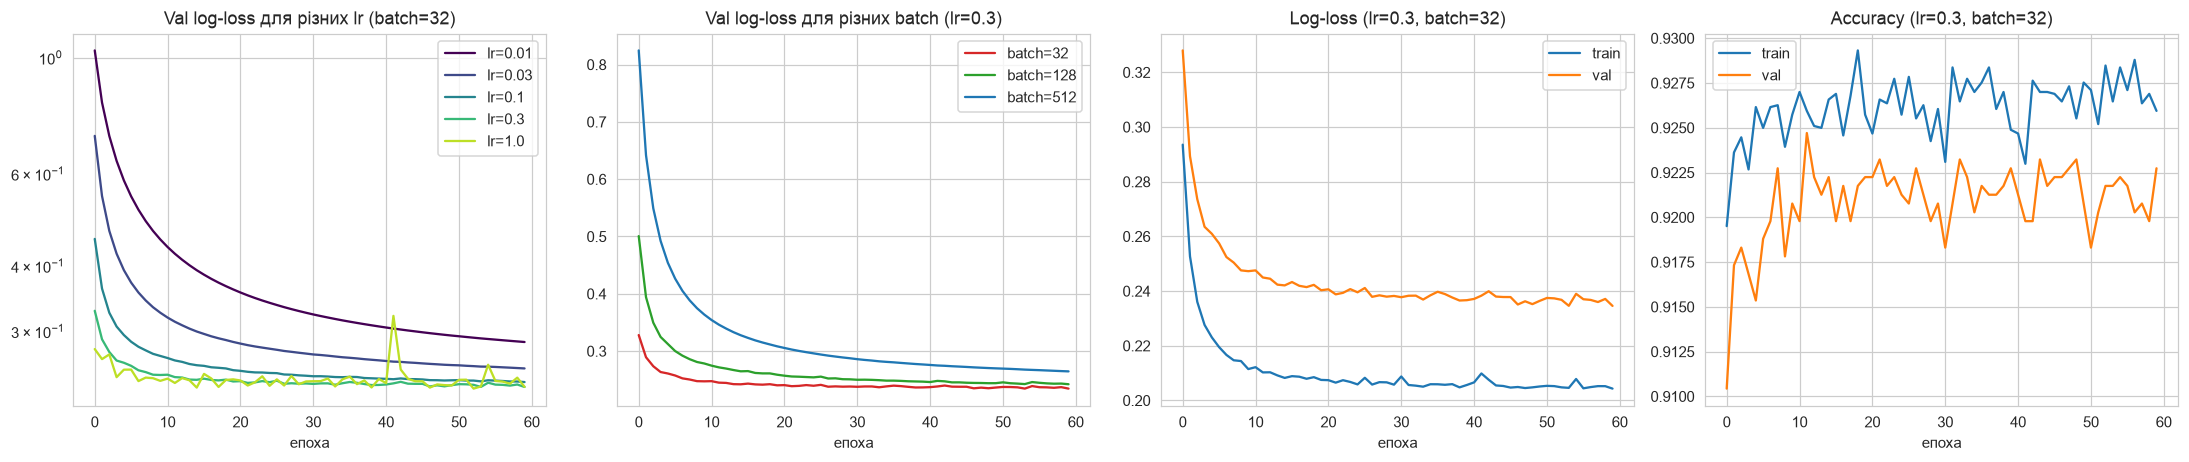

In [18]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.3))
for lr, c in zip(lr_grid, plt.cm.viridis(np.linspace(0, 0.9, len(lr_grid)))):
    ax[0].plot(curves[(lr, BS)]['val_loss'], c=c, label=f'lr={lr}')
ax[0].set_title(f'Val log-loss для різних lr (batch={BS})'); ax[0].set_xlabel('епоха'); ax[0].set_yscale('log'); ax[0].legend()
for bs, c in zip(bs_grid, ['tab:red', 'tab:green', 'tab:blue']):
    ax[1].plot(curves[(LR, bs)]['val_loss'], c=c, label=f'batch={bs}')
ax[1].set_title(f'Val log-loss для різних batch (lr={LR})'); ax[1].set_xlabel('епоха'); ax[1].legend()
h = curves[(LR, BS)]
ax[2].plot(h['train_loss'], label='train'); ax[2].plot(h['val_loss'], label='val')
ax[2].set_title(f'Log-loss (lr={LR}, batch={BS})'); ax[2].set_xlabel('епоха'); ax[2].legend()
ax[3].plot(h['train_acc'], label='train'); ax[3].plot(h['val_acc'], label='val')
ax[3].set_title(f'Accuracy (lr={LR}, batch={BS})'); ax[3].set_xlabel('епоха'); ax[3].legend()
plt.tight_layout(); plt.show()

**Що показано:** val log-loss після 60 епох для сітки lr × batch та криві навчання найкращої конфігурації.

**Закономірність:**
* Малий lr (0.01) і великий батч (512) дають повільну збіжність: за 60 епох модель не доходить до мінімуму
  (val log-loss 0.64 для lr=0.01, B=512).
* Зі зростанням lr і зменшенням батчу збіжність прискорюється.
* При lr = 0.3–1.0 усі розміри батчу виходять на плато val log-loss ≈ 0.235 і accuracy ≈ 92.3 %.
* При lr = 1.0 на кривій видно окремі сплески втрат.

**Чому:**
* Softmax-крос-ентропія опукла, тому при достатньому бюджеті всі конфігурації збігаються до того самого мінімуму.
  Різниця лише у швидкості.
* Малий батч дає більше оновлень за епоху, тож прогрес на епоху швидший.
* Великий lr з малим батчем робить шумні кроки, звідси сплески.

**Вибір:** lr = 0.3, batch = 32 — найнижчий val log-loss без нестабільності lr = 1.0.

Криві train/val майже паралельні, а розрив між ними малий (log-loss 0.204 vs 0.235, accuracy 92.6 % vs 92.3 %).
Отже, перенавчання немає: у моделі лише 77 параметрів (10·7 + 7) на 9.5 тис. прикладів.

### 3.2 Вплив Ridge-регуляризації

,λ,train log-loss,val log-loss,train acc,val acc,val macro-F1,‖W‖_F
0,0.0000,0.2043,0.2353,0.9259,0.9227,0.9310,16.7359
1,0.0000,0.2044,0.2355,0.9259,0.9227,0.9310,16.5032
2,0.0001,0.2061,0.2380,0.9250,0.9247,0.9330,14.8795
3,0.0010,0.2286,0.2632,0.9245,0.9203,0.9285,10.2438
4,0.0030,0.2667,0.2990,0.9207,0.9208,0.9290,7.8618
5,0.0100,0.3537,0.3810,0.9181,0.9114,0.9194,5.5281
6,0.0300,0.4977,0.5200,0.9042,0.8971,0.9054,3.7603
7,0.1000,0.7464,0.7636,0.8229,0.8145,0.8309,2.2904


Найкраще λ за val log-loss: 0.0


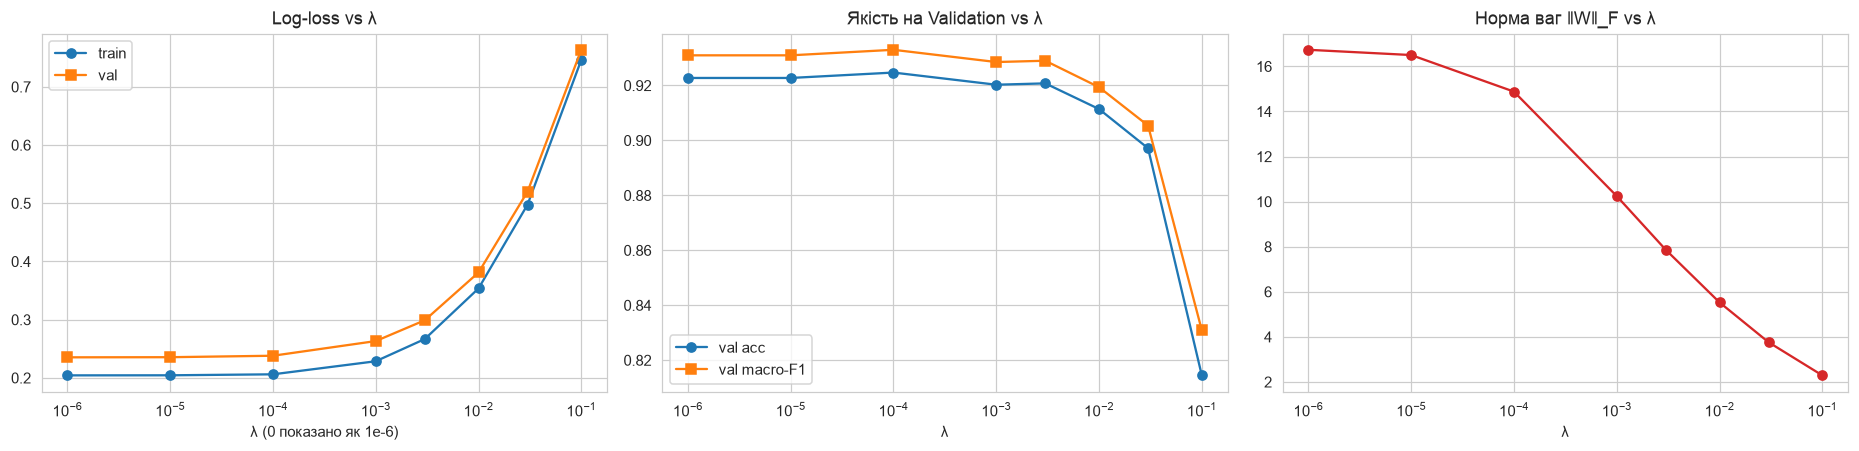

In [19]:
lam_grid = [0, 1e-5, 1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1]
lam_rows, lam_models = [], {}
for lam in lam_grid:
    mdl = SoftmaxRegression(len(FEATURES), C, lam=lam).fit(X_pool, y_pool, EPOCHS_C, BS, LR, X_val, y_val)
    lam_models[lam] = mdl
    ev_tr, ev_va = evaluate(mdl, X_pool, y_pool), evaluate(mdl, X_val, y_val)
    lam_rows.append({'λ': lam, 'train log-loss': ev_tr['log-loss'], 'val log-loss': ev_va['log-loss'],
                     'train acc': ev_tr['accuracy'], 'val acc': ev_va['accuracy'], 'val macro-F1': ev_va['macro-F1'],
                     '‖W‖_F': np.linalg.norm(mdl.W)})
lam_tab = pd.DataFrame(lam_rows)
display(lam_tab.round(4))
LAM = float(lam_tab.sort_values('val log-loss').iloc[0]['λ'])
print('Найкраще λ за val log-loss:', LAM)

x = np.array([1e-6] + lam_grid[1:])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(x, lam_tab['train log-loss'], 'o-', label='train'); ax[0].plot(x, lam_tab['val log-loss'], 's-', label='val')
ax[0].set_xscale('log'); ax[0].set_xlabel('λ (0 показано як 1e-6)'); ax[0].set_title('Log-loss vs λ'); ax[0].legend()
ax[1].plot(x, lam_tab['val acc'], 'o-', label='val acc'); ax[1].plot(x, lam_tab['val macro-F1'], 's-', label='val macro-F1')
ax[1].set_xscale('log'); ax[1].set_xlabel('λ'); ax[1].set_title('Якість на Validation vs λ'); ax[1].legend()
ax[2].plot(x, lam_tab['‖W‖_F'], 'o-', c='tab:red'); ax[2].set_xscale('log'); ax[2].set_xlabel('λ'); ax[2].set_title('Норма ваг ‖W‖_F vs λ')
plt.tight_layout(); plt.show()

**Що показано:** як λ впливає на log-loss, accuracy/macro-F1 і норму ваг $\lVert W\rVert_F$.

**Закономірність:**
* Норма ваг монотонно спадає (16.7 → 2.3), тобто штраф справді «стискає» ваги до нуля.
* При $\lambda \le 10^{-4}$ якість майже не змінюється: val log-loss 0.235–0.238, val macro-F1 0.931–0.933.
* Далі і train-, і val-log-loss ростуть разом, а при $\lambda = 0.1$ accuracy падає до 81 %. Це недонавчання:
  штраф заважає моделі розділяти класи.

**Чому:** регуляризація бореться з *дисперсією* (перенавчанням). Тут дисперсії майже немає — модель проста,
даних багато, розрив train/val малий. Тому Ridge нічого не виграє, а великий λ лише додає зміщення (bias).
Обидві криві log-loss ростуть одночасно — ознака саме bias, а не overfitting.

**Вибір:** за критерієм мінімального val log-loss $\lambda = 0$ (значення $10^{-5}$ дає практично те саме).
Класи BOMBAY майже лінійно відокремлюються від решти, тож без штрафу ваги для них ростуть. Проте на Validation це
не шкодить. Регуляризація була б корисною при меншій кількості даних, як-от у маленьких клієнтів у FL.

### 3.3 Перевірка відбору ознак (на Validation)

In [20]:
mu16, sd16 = server_aggregate_stats([client_stats(pool_df[FEATURES_ALL].to_numpy(float)[p]) for p in parts_iid5])
X16_pool = (pool_df[FEATURES_ALL].to_numpy(float) - mu16) / sd16
X16_val = (val_df[FEATURES_ALL].to_numpy(float) - mu16) / sd16
m16 = SoftmaxRegression(16, C, lam=LAM).fit(X16_pool, y_pool, EPOCHS_C, BS, LR, record=False)
m10 = SoftmaxRegression(len(FEATURES), C, lam=LAM).fit(X_pool, y_pool, EPOCHS_C, BS, LR, record=False)
print(pd.DataFrame({'усі 16 ознак': evaluate(m16, X16_val, y_val), f'{len(FEATURES)} відібраних': evaluate(m10, X_val, y_val)}).round(4))
Hc16 = np.cov(X16_pool.T); Hc10 = np.cov(X_pool.T)
print(f'\nЧисло обумовленості кореляційної матриці: 16 ознак = {np.linalg.cond(Hc16):.0f}, {len(FEATURES)} ознак = {np.linalg.cond(Hc10):.0f}')

              усі 16 ознак  10 відібраних
accuracy            0.9232         0.9227
macro-F1            0.9315         0.9310
balanced acc        0.9311         0.9309
log-loss            0.2353         0.2353

Число обумовленості кореляційної матриці: 16 ознак = 5043737, 10 ознак = 13211


**Висновок:** 10 відібраних ознак дають ту саму якість, що й усі 16: accuracy 0.9227 vs 0.9232,
log-loss однаковий — 0.2353. Число обумовленості кореляційної матриці при цьому падає з ~$5\cdot10^6$ до ~$1.3\cdot10^4$.

Відкинуті ознаки були майже точними функціями залишених: `ConvexArea` ≈ `Area` ($r=1.000$), `Compactness` ↔ `AspectRation`
($r=-0.988$). Тому вони не несли нової інформації. Натомість вони робили задачу гірше обумовленою: градієнтний спуск повільніший,
ваги нестабільні й неінтерпретовані. Відбір виконано лише на FL Train Pool, а перевірку — на Validation, тож Test не
використовувався.

### 3.4 Фінальна централізована модель: оцінка на Global Test

Централізована модель на Global Test:
accuracy        0.9183
macro-F1        0.9305
balanced acc    0.9313
log-loss        0.2294
dtype: float64


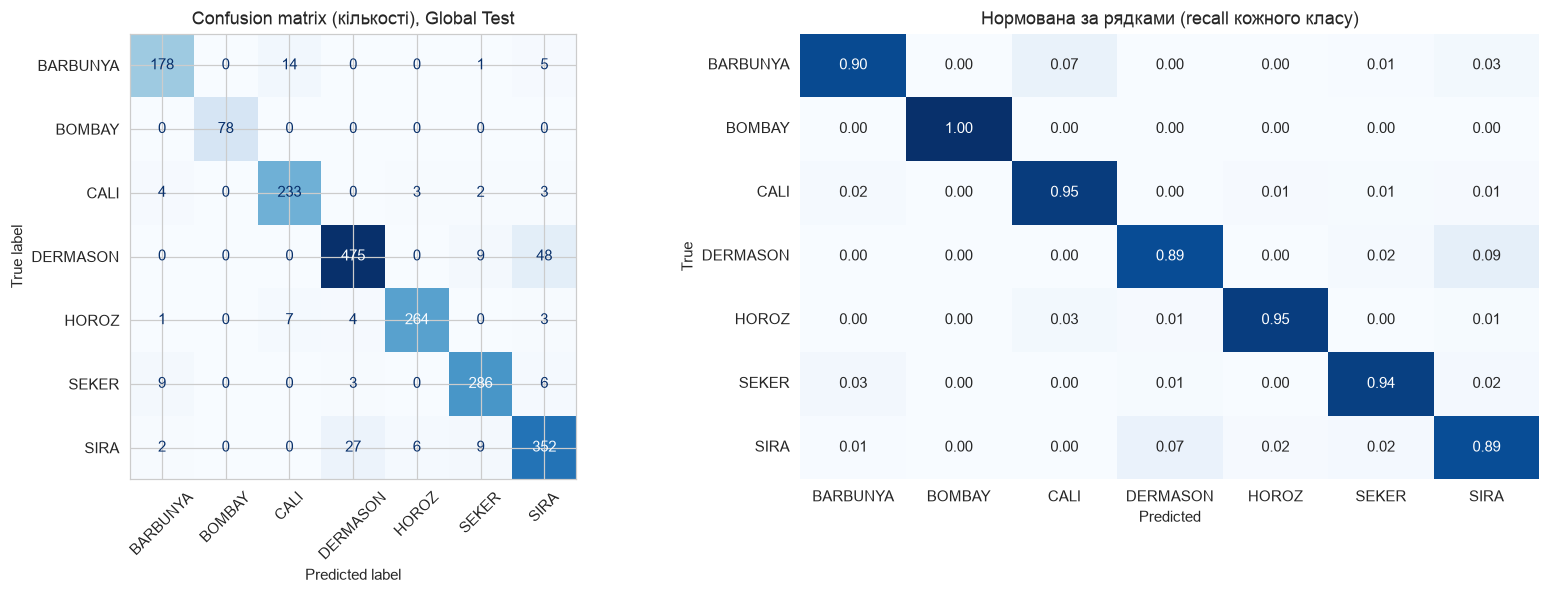

BARBUNYA    0.908
BOMBAY      1.000
CALI        0.934
DERMASON    0.913
HOROZ       0.957
SEKER       0.936
SIRA        0.866
Name: F1 по класах, dtype: float64


In [21]:
central = SoftmaxRegression(len(FEATURES), C, lam=LAM).fit(X_pool, y_pool, EPOCHS_C, BS, LR, X_val, y_val)
central_test = evaluate(central, X_test, y_test)
print('Централізована модель на Global Test:')
print(pd.Series(central_test).round(4))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
cm = confusion_matrix(y_test, central.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap='Blues', colorbar=False, xticks_rotation=45)
ax[0].set_title('Confusion matrix (кількості), Global Test')
cmn = cm / cm.sum(1, keepdims=True)
sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], cbar=False)
ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('True'); ax[1].set_title('Нормована за рядками (recall кожного класу)')
plt.tight_layout(); plt.show()
print(pd.Series(f1_score(y_test, central.predict(X_test), average=None), index=CLASSES, name='F1 по класах').round(3))

Централізована модель, навчена на всьому пулі тренувальних даних (FL Train Pool), слугує "золотим стандартом" для порівняння з федеративними підходами.Аналіз метрик: Модель демонструє високі показники Accuracy, Macro-F1 та Balanced Accuracy. Високі значення Macro-F1 та Balanced Accuracy (порівняно з простою Accuracy) свідчать про те, що модель добре справляється з класифікацією навіть для менш представлених класів (наприклад, BOMBAY), незважаючи на загальний дисбаланс у датасеті.Матриця помилок: Візуалізація показує, що найбільше помилок модель робить між схожими класами (наприклад, плутає сорти DERMASON та SIRA).Вплив Ridge-регуляризації: Використання $L2$ регуляризації допомагає уникнути перенавчання (штрафуючи завеликі ваги) та стабілізує модель за наявності мультиколінеарних ознак (яких багато у геометричних вимірах квасолі). Зверніть увагу, що параметр зміщення $b$ зазвичай не регуляризують, оскільки штраф за зсув не впливає на складність розділяючої гіперплощини, а лише зміщує її.

**Результат на Global Test:** accuracy 0.918, macro-F1 0.931, balanced accuracy 0.931, log-loss 0.229.

**Confusion matrix:**
* BOMBAY розпізнається ідеально (F1 = 1.00): це найбільші зерна, вони лінійно відокремлюються за площею.
* Основні помилки — пара DERMASON ↔ SIRA. 48 DERMASON передбачено як SIRA і 27 SIRA як DERMASON. Ці сорти мають
  близькі розміри й форму, тож лінійна межа між ними неминуче помиляється. Звідси найнижчий F1 у SIRA (0.87).
* Друга помітна пара — BARBUNYA ↔ CALI: 14 BARBUNYA передбачено як CALI.

**Про метрики:** macro-F1 і balanced accuracy тут *вищі* за accuracy. Малий клас BOMBAY класифікується ідеально, а в
macro-усередненні він має таку саму вагу, як великий DERMASON з помилками. Accuracy натомість домінують великі класи.
Log-loss 0.23 означає, що модель добре відкалібрована: вона не лише вгадує клас, а й дає адекватні ймовірності.

Ця модель — **верхній орієнтир (baseline)** для федеративного навчання: FedAvg в ідеалі має до неї наблизитися.

## Етап 4. Розподіл даних між клієнтами та сервером

### 4.1 Архітектура системи

```
                         ┌──────────────────────────── СЕРВЕР ────────────────────────────┐
                         │  Global Validation (моніторинг, гіперпараметри)                │
                         │  Global Test (лише фінальна оцінка)                            │
                         │  Глобальна модель (W, b);  агрегує (μ_k, σ²_k, n_k) та (W_k, b_k)│
                         └───────▲──────────────┬──────────────────────────────▲─────────┘
               W_k, b_k, n_k     │              │  W^t, b^t (лише глобальна)   │
                         ┌───────┴───┐   ┌──────▼────┐                  ┌──────┴────┐
                         │ Клієнт 1  │   │ Клієнт 2  │       ...        │ Клієнт K  │
                         │   D_1     │   │   D_2     │                  │   D_K     │
                         └───────────┘   └───────────┘                  └───────────┘
                           FL Train Pool розбитий на D_1 … D_K (кожен приклад — рівно в одному D_k)
```

| Учасник | Має доступ | НЕ має доступу |
|---|---|---|
| Сервер | Global Test, Global Validation, параметри моделей від клієнтів, агрегати $(n_k,\mu_k,\sigma_k^2)$ | сирі дані клієнтів, локальні вибірки |
| Клієнт $k$ | власна $D_k$; глобальна модель від сервера; глобальні $(\mu,\sigma)$ | Global Test/Validation, дані та моделі інших клієнтів |

У коді це забезпечено структурою класів: об'єкт `Client` зберігає лише свої `X, y` і повертає тільки `(params, n_k)`;
об'єкт `Server` зберігає лише Validation/Test і глобальні параметри.

### 4.2 Розподіли, що досліджуються

$K = 5$ клієнтів; IID та Діріхле з $\alpha \in \{5, 1, 0.3\}$ (+ $\alpha=0.1$ як екстремальний випадок). Seed фіксований.

In [22]:
K = 5
MIN_SIZE = 10
partitions = {'IID': (iid_partition(y_pool, K), 1)}
for a in [5, 1, 0.3, 0.1]:
    partitions[f'α={a}'] = dirichlet_partition(y_pool, K, alpha=a, min_size=MIN_SIZE)
for name, (parts, att) in partitions.items():
    check_partition(parts, len(y_pool))

def partition_table(parts, y):
    tab = pd.DataFrame([np.bincount(y[p], minlength=C) for p in parts],
                       index=[f'client {k}' for k in range(len(parts))], columns=CLASSES)
    tab['n_k (всього)'] = tab.sum(axis=1)
    return tab

for name, (parts, att) in partitions.items():
    tab = partition_table(parts, y_pool)
    print(f'=== {name}  (спроб генерації: {att}; мін. n_k = {tab["n_k (всього)"].min()}; '
          f'клієнтів з n_k < {MIN_SIZE}: {(tab["n_k (всього)"] < MIN_SIZE).sum()})')
    display(tab)

=== IID  (спроб генерації: 1; мін. n_k = 1894; клієнтів з n_k < 10: 0)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k (всього)
client 0,185,73,228,497,260,284,368,1895
client 1,185,73,228,496,260,284,369,1895
client 2,185,73,228,496,260,283,369,1894
client 3,186,73,228,496,261,284,369,1897
client 4,185,74,228,497,261,284,369,1898


=== α=5  (спроб генерації: 1; мін. n_k = 1590; клієнтів з n_k < 10: 0)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k (всього)
client 0,163,65,229,836,172,163,254,1882
client 1,228,32,166,518,233,379,340,1896
client 2,249,61,55,251,512,315,147,1590
client 3,166,82,454,205,171,232,787,2097
client 4,120,126,236,672,214,330,316,2014


=== α=1  (спроб генерації: 1; мін. n_k = 1240; клієнтів з n_k < 10: 0)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k (всього)
client 0,317,34,52,992,196,168,56,1815
client 1,3,9,62,989,105,72,32,1272
client 2,297,71,1,176,564,253,1294,2656
client 3,281,127,764,136,368,710,110,2496
client 4,28,125,261,189,69,216,352,1240


=== α=0.3  (спроб генерації: 1; мін. n_k = 1046; клієнтів з n_k < 10: 0)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k (всього)
client 0,83,132,0,206,960,124,0,1505
client 1,0,25,205,38,0,1096,172,1536
client 2,813,2,245,57,29,138,32,1316
client 3,7,138,54,0,5,0,842,1046
client 4,23,69,636,2181,308,61,798,4076


=== α=0.1  (спроб генерації: 2; мін. n_k = 647; клієнтів з n_k < 10: 0)


,BARBUNYA,BOMBAY,CALI,DERMASON,HOROZ,SEKER,SIRA,n_k (всього)
client 0,149,0,0,622,0,1,174,946
client 1,0,254,1139,1810,0,17,22,3242
client 2,0,0,0,0,1301,128,0,1429
client 3,583,0,0,49,0,15,0,647
client 4,194,112,1,1,1,1258,1648,3215


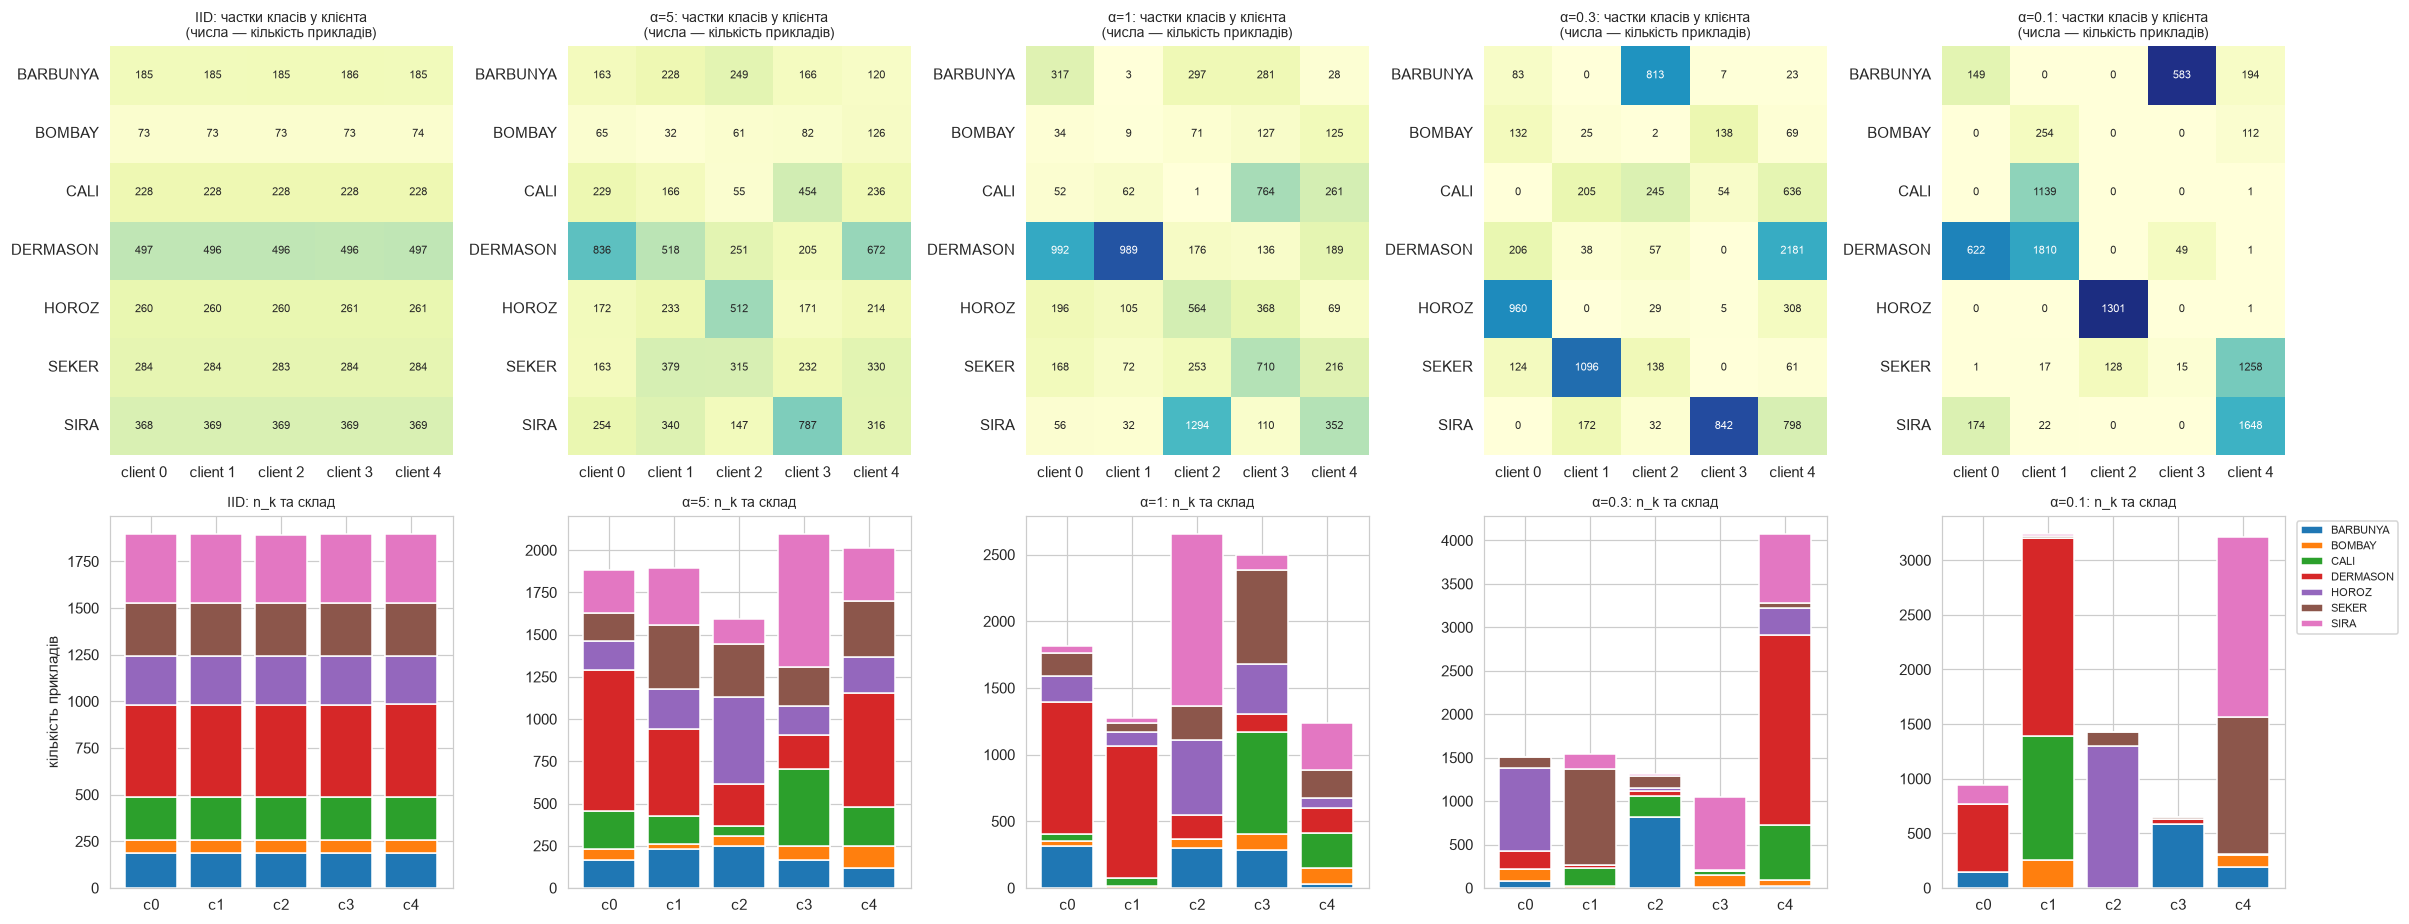

In [23]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8.5), gridspec_kw={'height_ratios': [1.1, 1]})
for j, (name, (parts, _)) in enumerate(partitions.items()):
    tab = partition_table(parts, y_pool)
    frac = tab[CLASSES].div(tab[CLASSES].sum(axis=1), axis=0)
    sns.heatmap(frac.T, annot=tab[CLASSES].T, fmt='d', cmap='YlGnBu', vmin=0, vmax=1, cbar=False,
                ax=axes[0, j], annot_kws={'size': 7})
    axes[0, j].set_title(f'{name}: частки класів у клієнта\n(числа — кількість прикладів)', fontsize=9)
    bottom = np.zeros(K)
    for ci, cname in enumerate(CLASSES):
        axes[1, j].bar(range(K), tab[cname], bottom=bottom, color=sns.color_palette('tab10', C)[ci], label=cname)
        bottom += tab[cname].to_numpy()
    axes[1, j].set_xticks(range(K)); axes[1, j].set_xticklabels([f'c{k}' for k in range(K)])
    axes[1, j].set_title(f'{name}: n_k та склад', fontsize=9)
axes[1, 0].set_ylabel('кількість прикладів'); axes[1, -1].legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()

IID розподіл: У цьому сценарії дані рівномірно перемішані. Кожен клієнт отримує репрезентативну міні-версію глобального датасету зі збереженням балансу класів.Non-IID розподіл (розподіл Діріхле): Ми використали розподіл Діріхле для імітації реалістичного "острівного" накопичення даних. Як видно з візуалізації (при alpha = 0.3), деякі клієнти мають переважно дані одного-двох сортів, тоді як інші класи у них майже відсутні.Вплив на федеративне навчання: Неоднорідний розподіл є головним викликом FL. Локальні моделі будуть сильно "перекошені" (overfit) під ті класи, які переважають у конкретного клієнта.

**Що показано:** склад і розмір даних кожного з 5 клієнтів для п'яти сценаріїв. Кожна таблиця вище документує точний розподіл:
кількість прикладів кожного класу в кожного клієнта. Для всіх розподілів `check_partition` підтвердив, що кожен приклад
належить рівно одному клієнту. Клієнтів з $n_k < 10$ немає — мінімальний $n_k$ = 647 навіть при α = 0.1.

**Закономірність:**
* **IID:** у всіх клієнтів ~1895 прикладів і однакові пропорції класів.
* **α = 5:** пропорції вже помітно «гуляють» (DERMASON від 205 до 836), але всі класи є в усіх.
* **α = 1:** з'являються клієнти, де клас майже відсутній: client 1 має 3 BARBUNYA, client 2 — 1 CALI.
* **α = 0.3:** кожен клієнт «спеціалізується» на 1–2 сортах (client 0 — HOROZ, client 1 — SEKER, client 3 — SIRA).
  З'являються нулі, і розміри теж різняться сильніше: від 1046 до 4076.
* **α = 0.1:** клієнти мають по 2–4 класи. Наприклад, client 2 бачить майже лише HOROZ, а BOMBAY є тільки у двох клієнтів.

**Чому:** Діріхле з малим α генерує «розріджені» вектори пропорцій — майже вся маса класу дістається одному клієнту.
Великий α дає пропорції, близькі до рівних $1/K$.

**Вплив на глобальну модель.** Кожен клієнт мінімізує *власну* функцію втрат, яка при сильному перекосі класів має
мінімум далеко від глобального:
* клієнт, що не бачить класу, «вчиться» ніколи його не передбачати (зсув $b$ для цього класу йде вниз);
* після усереднення такі протилежні зсуви частково компенсуються, але глобальна модель збігається повільніше і до гіршої точки.

Це кількісно перевірено в Експерименті 1.

## Етап 5. Симуляція федеративного навчання (FedAvg)

1. Сервер ініціалізує $w^0$ (нулі). 2. На раунді $t$ обирає клієнтів $S_t$ (тут — усіх, `frac=1.0`).
3. Розсилає $w^t$. 4. Кожен клієнт навчає копію $E$ локальних епох міні-батчевим GD, стартуючи з $w^t$.
5. Повертає $(w_k^{t+1}, n_k)$. 6. Сервер агрегує
$$w^{t+1} = \sum_{k\in S_t}\frac{n_k}{\sum_{j\in S_t} n_j}\,w_k^{t+1}\qquad(\text{окремо для } W \text{ і } b).$$
7. Оцінка на Global Validation після кожного раунду.

Додатково логуємо **client drift** — середню відстань $\frac1{|S_t|}\sum_k \lVert W_k^{t+1} - W^{t+1}\rVert_F$ локальних
моделей від агрегованої.

In [24]:
class Client:
    # Клієнт: зберігає ЛИШЕ власні дані, отримує від сервера лише глобальні параметри
    def __init__(self, cid, X, y, seed):
        self._X, self._y = X, y               # приватні дані клієнта
        self.cid, self.n = cid, len(y)
        self.rng = np.random.default_rng(seed)

    def local_train(self, global_params, epochs, lr, batch_size, lam):
        model = SoftmaxRegression(self._X.shape[1], C, lam=lam, seed=int(self.rng.integers(1 << 31)))
        model.set_params(global_params)       # старт з глобальної моделі
        model.fit(self._X, self._y, epochs=epochs, batch_size=batch_size, lr=lr, record=False)
        return model.get_params(), self.n     # назад іде лише (W, b) та n_k

    def train_local_only(self, epochs, lr, batch_size, lam):
        # «Суто локальна» модель: клієнт навчається лише на своїх даних, без FL
        model = SoftmaxRegression(self._X.shape[1], C, lam=lam, seed=self.cid)
        return model.fit(self._X, self._y, epochs=epochs, batch_size=batch_size, lr=lr, record=False)


class Server:
    # Сервер: має Global Validation/Test і глобальну модель; сирих даних клієнтів не має
    def __init__(self, d, X_val, y_val, X_test, y_test, lam, seed=SEED):
        self.model = SoftmaxRegression(d, C, lam=lam)
        self._val, self._test = (X_val, y_val), (X_test, y_test)
        self.rng = np.random.default_rng(seed)

    def select_clients(self, clients, frac=1.0):
        k = max(1, int(round(frac * len(clients))))
        return list(self.rng.choice(clients, size=k, replace=False)) if k < len(clients) else list(clients)

    @staticmethod
    def aggregate(updates, weighting='n_k'):
        # FedAvg: зважене середнє параметрів; weighting='uniform' — просте середнє (для порівняння)
        n = np.array([nk for _, nk in updates], float)
        w = n / n.sum() if weighting == 'n_k' else np.ones(len(n)) / len(n)
        W = sum(wi * p['W'] for wi, (p, _) in zip(w, updates))
        b = sum(wi * p['b'] for wi, (p, _) in zip(w, updates))
        return {'W': W, 'b': b}

    def evaluate_val(self):  return evaluate(self.model, *self._val)
    def evaluate_test(self): return evaluate(self.model, *self._test)


def make_clients(parts, X, y, seed=SEED):
    return [Client(k, X[p], y[p], seed + 1000 * k) for k, p in enumerate(parts)]


def run_fedavg(clients, rounds=40, E=5, lr=None, batch_size=None, lam=None, weighting='n_k', frac=1.0, seed=SEED, verbose=False):
    lr, batch_size, lam = lr or LR, batch_size or BS, LAM if lam is None else lam
    server = Server(X_val.shape[1], X_val, y_val, X_test, y_test, lam, seed)
    hist = {'val_loss': [], 'val_acc': [], 'val_f1': [], 'drift': []}
    for t in range(rounds):
        S_t = server.select_clients(clients, frac)
        g = server.model.get_params()
        updates = [c.local_train(g, E, lr, batch_size, lam) for c in S_t]
        new = server.aggregate(updates, weighting)
        hist['drift'].append(np.mean([np.linalg.norm(p['W'] - new['W']) for p, _ in updates]))
        server.model.set_params(new)
        ev = server.evaluate_val()
        hist['val_loss'].append(ev['log-loss']); hist['val_acc'].append(ev['accuracy']); hist['val_f1'].append(ev['macro-F1'])
        if verbose and (t + 1) % 10 == 0:
            print(f'раунд {t + 1:3d}: val acc = {ev["accuracy"]:.4f}, val log-loss = {ev["log-loss"]:.4f}')
    server.history = hist
    return server

**Перевірка агрегації на простому прикладі.** Два клієнти з $n_1=100$, $n_2=300$ і вагами $W_1=\mathbf{1}$, $W_2=\mathbf{5}$:
зважене середнє має дати $0.25\cdot1+0.75\cdot5 = 4$, просте — $3$.

In [25]:
upd = [({'W': np.ones((2, 2)), 'b': np.ones((1, 2))}, 100), ({'W': 5 * np.ones((2, 2)), 'b': 5 * np.ones((1, 2))}, 300)]
print('FedAvg (зважене):', Server.aggregate(upd)['W'][0, 0], ' | просте середнє:', Server.aggregate(upd, 'uniform')['W'][0, 0])

FedAvg (зважене): 4.0  | просте середнє: 3.0


### 5.1 Базовий запуск FedAvg: IID та α = 1

Гіперпараметри локального навчання — ті ж, що й у централізованої моделі (lr, batch, λ); $E=5$, $T=40$ раундів.

IID: 2.8 c, фінальна val acc = 0.9227
α=1: 3.2 c, фінальна val acc = 0.9257


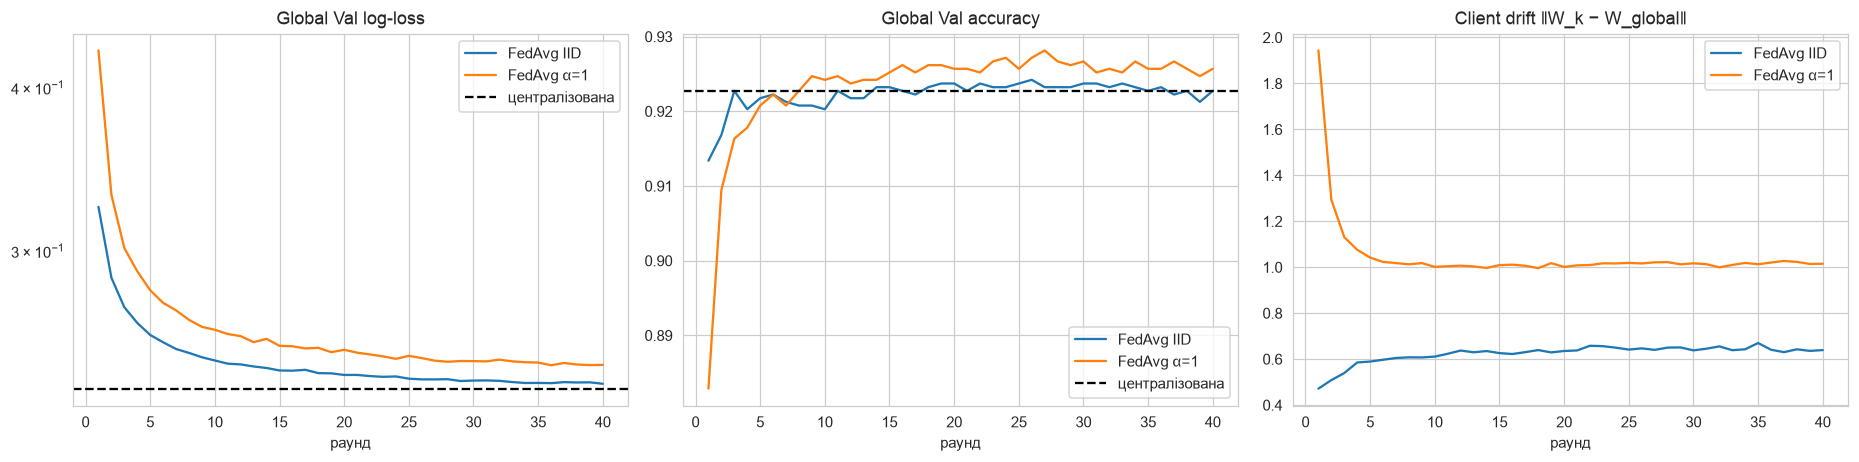

In [26]:
ROUNDS, E_BASE = 40, 5
base_runs = {}
for name in ['IID', 'α=1']:
    t0 = time.perf_counter()
    base_runs[name] = run_fedavg(make_clients(partitions[name][0], X_pool, y_pool), ROUNDS, E_BASE)
    print(f'{name}: {time.perf_counter() - t0:.1f} c, фінальна val acc = {base_runs[name].history["val_acc"][-1]:.4f}')

c_val = evaluate(central, X_val, y_val)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
for name, c in zip(base_runs, ['tab:blue', 'tab:orange']):
    h = base_runs[name].history
    ax[0].plot(range(1, ROUNDS + 1), h['val_loss'], c=c, label=f'FedAvg {name}')
    ax[1].plot(range(1, ROUNDS + 1), h['val_acc'], c=c, label=f'FedAvg {name}')
    ax[2].plot(range(1, ROUNDS + 1), h['drift'], c=c, label=f'FedAvg {name}')
ax[0].axhline(c_val['log-loss'], c='k', ls='--', label='централізована'); ax[1].axhline(c_val['accuracy'], c='k', ls='--', label='централізована')
for a, t in zip(ax, ['Global Val log-loss', 'Global Val accuracy', 'Client drift ‖W_k − W_global‖']):
    a.set_title(t); a.set_xlabel('раунд'); a.legend()
ax[0].set_yscale('log'); plt.tight_layout(); plt.show()

**Що показано:** якість глобальної моделі на Global Validation після кожного раунду та client drift.

**Закономірність:**
* У сценарії IID глобальна модель майже одразу (2–3 раунди) досягає ~92 % accuracy, а val log-loss до 40-го раунду
  майже доходить до централізованого рівня.
* Для α = 1 старт повільніший: після 1-го раунду accuracy лише 88 %, log-loss вищий. Але приблизно до 10-го раунду
  модель наздоганяє.
* Drift для α = 1 стабілізується на рівні ~1.0 проти ~0.6 для IID.

**Чому:** в IID локальні градієнти в середньому збігаються з глобальним, тож усереднення локальних моделей ≈ крок
централізованого SGD. При α = 1 клієнти тягнуть модель у різні боки. Перші раунди витрачаються на узгодження, а
ненульовий drift навіть біля збіжності показує: мінімуми клієнтів різні.

**Практичний висновок:** FedAvg на цьому датасеті працює майже без втрат при помірній неоднорідності, але потребує більше раундів.

## Етап 6. Дослідження ефектів федеративного навчання

### 6.1 Порівняння: локальні vs глобальна vs централізована моделі (α = 1)

Локальні моделі навчаються лише на даних свого клієнта ($E_{loc}$ = стільки ж епох, скільки в централізованої, з тими ж
гіперпараметрами). Усі моделі оцінюються на тому самому Global Test.

In [27]:
def compare_models(parts, fed_server, label):
    rows = []
    clients = make_clients(parts, X_pool, y_pool)
    for c in clients:
        loc = c.train_local_only(EPOCHS_C, LR, BS, LAM)
        present = np.unique(c._y)
        r = {'Модель': f'Локальна (client {c.cid}, n={c.n}, класів={len(present)})', **evaluate(loc, X_test, y_test)}
        rows.append(r)
    rows.append({'Модель': f'Глобальна FedAvg ({label})', **fed_server.evaluate_test()})
    rows.append({'Модель': 'Централізована', **central_test})
    return pd.DataFrame(rows).set_index('Модель')

cmp_alpha1 = compare_models(partitions['α=1'][0], base_runs['α=1'], 'α=1')
cmp_iid = compare_models(partitions['IID'][0], base_runs['IID'], 'IID')
print('Global Test, розподіл α = 1:'); display(cmp_alpha1.round(4))
print('Global Test, розподіл IID:'); display(cmp_iid.round(4))

Global Test, розподіл α = 1:


,accuracy,macro-F1,balanced acc,log-loss
Модель,,,,
"Локальна (client 0, n=1815, класів=7)",0.8671,0.8819,0.8876,0.3684
"Локальна (client 1, n=1272, класів=7)",0.8086,0.8058,0.8085,0.5210
"Локальна (client 2, n=2656, класів=7)",0.7776,0.7242,0.7880,1.0780
"Локальна (client 3, n=2496, класів=7)",0.8883,0.9038,0.9108,0.3091
"Локальна (client 4, n=1240, класів=7)",0.8937,0.9042,0.9028,0.3097
Глобальна FedAvg (α=1),0.9139,0.9269,0.9291,0.2373
Централізована,0.9183,0.9305,0.9313,0.2294


Global Test, розподіл IID:


,accuracy,macro-F1,balanced acc,log-loss
Модель,,,,
"Локальна (client 0, n=1895, класів=7)",0.9163,0.9272,0.9273,0.2427
"Локальна (client 1, n=1895, класів=7)",0.9163,0.9286,0.9293,0.2388
"Локальна (client 2, n=1894, класів=7)",0.9104,0.9226,0.9226,0.2627
"Локальна (client 3, n=1897, класів=7)",0.9158,0.9272,0.9266,0.2360
"Локальна (client 4, n=1898, класів=7)",0.9119,0.9254,0.9261,0.2520
Глобальна FedAvg (IID),0.9163,0.9282,0.9282,0.2306
Централізована,0.9183,0.9305,0.9313,0.2294


**Що показано:** якість на Global Test для локальних моделей кожного клієнта, глобальної FedAvg і централізованої моделі.

**α = 1 (помірна неоднорідність):**
* Локальні моделі мають accuracy 0.78–0.89 і log-loss до 1.08.
* Глобальна FedAvg дає 0.914 / macro-F1 0.927 — краще за *кожну* локальну модель і лише на 0.4 п.п. гірше за централізовану (0.918).
* Найгірша локальна модель — client 2 (macro-F1 0.72), хоча в нього найбільше даних (2656). Він майже не бачив CALI
  (1 приклад), тому на глобальному тесті погано розпізнає цей клас. Розмір локальних даних не компенсує перекіс класів.

**IID:** усі локальні моделі вже майже такі ж, як централізована (0.910–0.916). Кожен клієнт має ~1900 репрезентативних
прикладів, а для 77 параметрів цього достатньо. Глобальна модель лише трохи краща.

**Чому так:** цінність FL зростає з неоднорідністю. Якщо дані клієнтів різні, жоден клієнт окремо не бачить повної картини.
FedAvg дозволяє «зібрати» знання всіх клієнтів в одну модель без обміну сирими даними.

### 6.2 Експеримент 1. Вплив неоднорідності даних (α)

Для надійності кожну конфігурацію повторюємо на **3 різних випадкових розподілах** (seed = 0, 1, 2) і усереднюємо.
Для кожного розподілу навчаються також локальні моделі (фіксуємо середню і найкращу з них).

In [28]:
SEEDS = [0, 1, 2]
ALPHAS = ['IID', 5, 1, 0.3, 0.1]
exp1_rows, exp1_hist = [], {}
t0 = time.perf_counter()
for a in ALPHAS:
    for s in SEEDS:
        parts = iid_partition(y_pool, K, seed=s) if a == 'IID' else dirichlet_partition(y_pool, K, alpha=a, seed=s, min_size=MIN_SIZE)[0]
        clients = make_clients(parts, X_pool, y_pool, seed=s)
        srv = run_fedavg(clients, ROUNDS, E_BASE, seed=s)
        exp1_hist[(a, s)] = srv.history
        loc = [evaluate(c.train_local_only(EPOCHS_C, LR, BS, LAM), X_test, y_test) for c in clients]
        g = srv.evaluate_test()
        exp1_rows.append({'α': str(a), 'seed': s, 'global acc': g['accuracy'], 'global macro-F1': g['macro-F1'],
                          'global bal acc': g['balanced acc'], 'global log-loss': g['log-loss'],
                          'local acc (середнє)': np.mean([l['accuracy'] for l in loc]),
                          'local acc (найкраща)': np.max([l['accuracy'] for l in loc]),
                          'local macro-F1 (середнє)': np.mean([l['macro-F1'] for l in loc]),
                          'local macro-F1 (найкраща)': np.max([l['macro-F1'] for l in loc]),
                          'мін. класів у клієнта': min(len(np.unique(y_pool[p])) for p in parts),
                          'drift (фінал)': srv.history['drift'][-1]})
print(f'Час експерименту: {time.perf_counter() - t0:.0f} c')
exp1 = pd.DataFrame(exp1_rows)
exp1_mean = exp1.drop(columns='seed').groupby('α', sort=False).mean()
exp1_std = exp1.drop(columns='seed').groupby('α', sort=False).std()
display(exp1_mean.round(4))
print('Стандартне відхилення за 3 seed:'); display(exp1_std[['global acc', 'global macro-F1', 'global log-loss']].round(4))

Час експерименту: 56 c


,global acc,global macro-F1,global bal acc,global log-loss,local acc (середнє),local acc (найкраща),local macro-F1 (середнє),local macro-F1 (найкраща),мін. класів у клієнта,drift (фінал)
α,,,,,,,,,,
IID,0.9167,0.9286,0.9284,0.2313,0.9143,0.9190,0.9264,0.9304,7.0000,0.5907
5,0.9177,0.9295,0.9294,0.2305,0.9111,0.9144,0.9232,0.9262,7.0000,0.6253
1,0.9160,0.9281,0.9276,0.2306,0.8712,0.9058,0.8772,0.9186,6.6667,0.8952
0.3,0.9131,0.9254,0.9252,0.2435,0.6900,0.8155,0.6551,0.7857,6.0000,1.3238
0.1,0.9026,0.9140,0.9143,0.2863,0.5203,0.6368,0.4226,0.5817,2.6667,1.5388


Стандартне відхилення за 3 seed:


,global acc,global macro-F1,global log-loss
α,,,
IID,0.0010,0.0007,0.0004
5,0.0008,0.0007,0.0014
1,0.0014,0.0011,0.0025
0.3,0.0041,0.0039,0.0100
0.1,0.0030,0.0037,0.0146


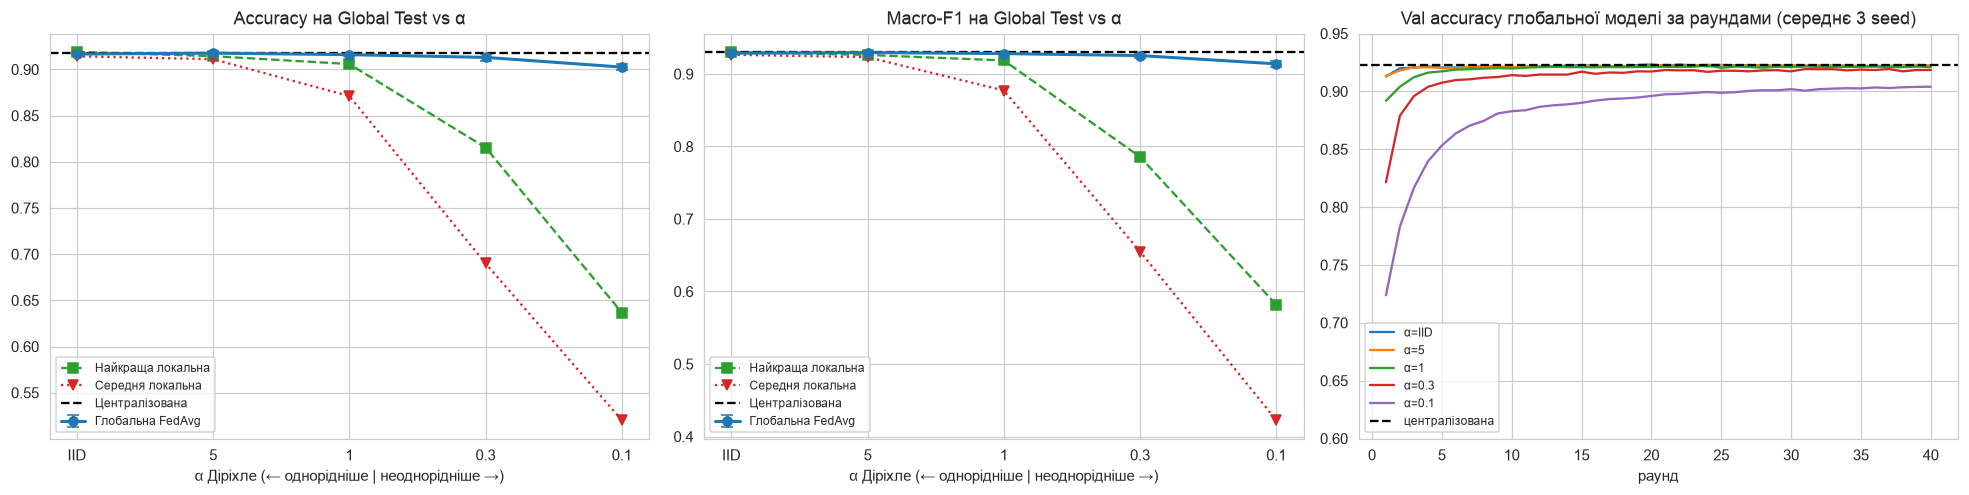

In [29]:
labels = [str(a) for a in ALPHAS]; xs = np.arange(len(labels))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for metric, loc_mean, loc_best, a_, title in [('global acc', 'local acc (середнє)', 'local acc (найкраща)', ax[0], 'Accuracy'),
                                             ('global macro-F1', 'local macro-F1 (середнє)', 'local macro-F1 (найкраща)', ax[1], 'Macro-F1')]:
    a_.errorbar(xs, exp1_mean[metric], yerr=exp1_std[metric], fmt='o-', c='tab:blue', lw=2, capsize=4, label='Глобальна FedAvg')
    a_.plot(xs, exp1_mean[loc_best], 's--', c='tab:green', label='Найкраща локальна')
    a_.plot(xs, exp1_mean[loc_mean], 'v:', c='tab:red', label='Середня локальна')
    a_.axhline(central_test['accuracy' if title == 'Accuracy' else 'macro-F1'], c='k', ls='--', label='Централізована')
    a_.set_xticks(xs); a_.set_xticklabels(labels); a_.set_xlabel('α Діріхле (← однорідніше | неоднорідніше →)')
    a_.set_title(f'{title} на Global Test vs α'); a_.legend(fontsize=8)
for a in ALPHAS:
    h = np.mean([exp1_hist[(a, s)]['val_acc'] for s in SEEDS], axis=0)
    ax[2].plot(range(1, ROUNDS + 1), h, label=f'α={a}')
ax[2].axhline(c_val['accuracy'], c='k', ls='--', label='централізована')
ax[2].set_title('Val accuracy глобальної моделі за раундами (середнє 3 seed)'); ax[2].set_xlabel('раунд'); ax[2].legend(fontsize=8)
ax[2].set_ylim(0.6, 0.95)
plt.tight_layout(); plt.show()

**Що показано:** фінальна якість на Global Test глобальної FedAvg, середньої та найкращої локальної моделі залежно від α
(середнє за 3 seed), і криві val accuracy за раундами.

**Закономірність:**

| α | Global acc | Global macro-F1 | Середня локальна acc | Найкраща локальна acc |
|---|---|---|---|---|
| IID | 0.917 | 0.929 | 0.914 | 0.919 |
| 5 | 0.918 | 0.930 | 0.911 | 0.914 |
| 1 | 0.916 | 0.928 | 0.871 | 0.906 |
| 0.3 | 0.913 | 0.925 | 0.690 | 0.816 |
| 0.1 | 0.903 | 0.914 | 0.523 | 0.637 |

* Глобальна модель деградує повільно: від IID до α = 0.3 втрачає лише ~0.4 п.п. accuracy, до α = 0.1 — ~1.4 п.п.
* Log-loss зростає помітніше (0.231 → 0.286), а розкид між seed зростає: std 0.001 → 0.004.
* Локальні моделі натомість обвалюються: середня падає з 0.914 до 0.523, бо клієнт з 2–3 класами просто не вміє розпізнавати решту.
* На кривих видно, що при α = 0.1 глобальна модель навіть за 40 раундів не досягає централізованого рівня.

**Чому Non-IID погіршує FL.** Мета — мінімізувати $\sum_k \frac{n_k}{N}J_k(w)$. Кожен клієнт робить $E$ епох по *своїй* $J_k$
і рухається до свого мінімуму $w_k^*$. При Non-IID ці мінімуми далеко один від одного, тож:
1. Середнє локальних моделей не збігається з кроком по глобальній функції — з'являється зміщення, і збіжність сповільнюється.
2. Усереднення моделей, кожна з яких «забула» частину класів, дає гірші межі між класами. Drift зростає з 0.59 (IID) до 1.54 (α = 0.1).
3. Рідкісні класи (BOMBAY) є лише в кількох клієнтів, тож їхній сигнал «розбавляється» при агрегації.

**Чи може глобальна модель бути гіршою за централізовану?** Так. У нашому експерименті вона гірша в усіх випадках
(0.903–0.918 проти 0.918), і розрив росте зі зменшенням α. Централізована модель робить кроки по справжньому глобальному
градієнту, а FedAvg — по усередненню зміщених локальних траєкторій. При IID різниця зникає, бо усереднення ≈ централізований SGD.

**Чи може глобальна модель бути гіршою за деякі локальні?**
* **На Global Test** — у нашому експерименті ні: при всіх α глобальна ≥ найкращої локальної (при IID 0.917 vs 0.919 — у межах шуму).
* **Теоретично та на локальних даних — так.** По-перше, якщо один клієнт має великий репрезентативний датасет, а решта — малі
  й перекошені, їхній внесок може погіршити модель. По-друге, на *локальному розподілі конкретного клієнта* спеціалізована
  локальна модель зазвичай краща за глобальну. Це прямо показано в Експерименті Б: на local-test клієнтів локальні моделі
  дають 0.961 accuracy проти 0.921 у глобальної.

### 6.3 Експеримент 2. Вплив кількості локальних епох (E)

$E \in \{1, 5, 10\}$ при однаковій кількості раундів $T = 40$; сценарії IID та сильно неоднорідний α = 0.3
(додатково α = 0.1, де ефект має бути найсильнішим). 3 seed на конфігурацію.

In [30]:
E_GRID = [1, 5, 10]
SCEN = ['IID', 0.3, 0.1]
exp2_rows, exp2_hist = [], {}
t0 = time.perf_counter()
for a in SCEN:
    for s in SEEDS:
        parts = iid_partition(y_pool, K, seed=s) if a == 'IID' else dirichlet_partition(y_pool, K, alpha=a, seed=s, min_size=MIN_SIZE)[0]
        for E in E_GRID:
            srv = run_fedavg(make_clients(parts, X_pool, y_pool, seed=s), ROUNDS, E, seed=s)
            exp2_hist[(a, E, s)] = srv.history
            g = srv.evaluate_test()
            exp2_rows.append({'сценарій': str(a), 'E': E, 'seed': s, 'test acc': g['accuracy'], 'test macro-F1': g['macro-F1'],
                              'test log-loss': g['log-loss'], 'drift (середній)': np.mean(srv.history['drift']),
                              'раундів до 0.90 val acc': next((i + 1 for i, v in enumerate(srv.history['val_acc']) if v >= 0.90), np.nan)})
print(f'Час експерименту: {time.perf_counter() - t0:.0f} c')
exp2 = pd.DataFrame(exp2_rows)
exp2_mean = exp2.drop(columns='seed').groupby(['сценарій', 'E'], sort=False).mean()
display(exp2_mean.round(4))

Час експерименту: 75 c


test acc  test macro-F1  test log-loss  drift (середній)  \
сценарій E                                                              
IID      1     0.9157         0.9278         0.2420            0.2094   
         5     0.9167         0.9286         0.2313            0.5781   
         10    0.9178         0.9304         0.2300            0.8626   
0.3      1     0.9117         0.9240         0.2536            0.8995   
         5     0.9131         0.9254         0.2435            1.4186   
         10    0.9108         0.9231         0.2447            1.6784   
0.1      1     0.9026         0.9113         0.2817            1.1127   
         5     0.9026         0.9140         0.2863            1.6824   
         10    0.8948         0.9070         0.3012            1.9480   

             раундів до 0.90 val acc  
сценарій E                            
IID      1                    2.0000  
         5                    1.0000  
         10                   1.0000  
0.3      1                    6.6667  
         5                    4.3333  
         10                   3.3333  
0.1      1                   22.0000  
         5                   25.6667  
         10                  24.5000

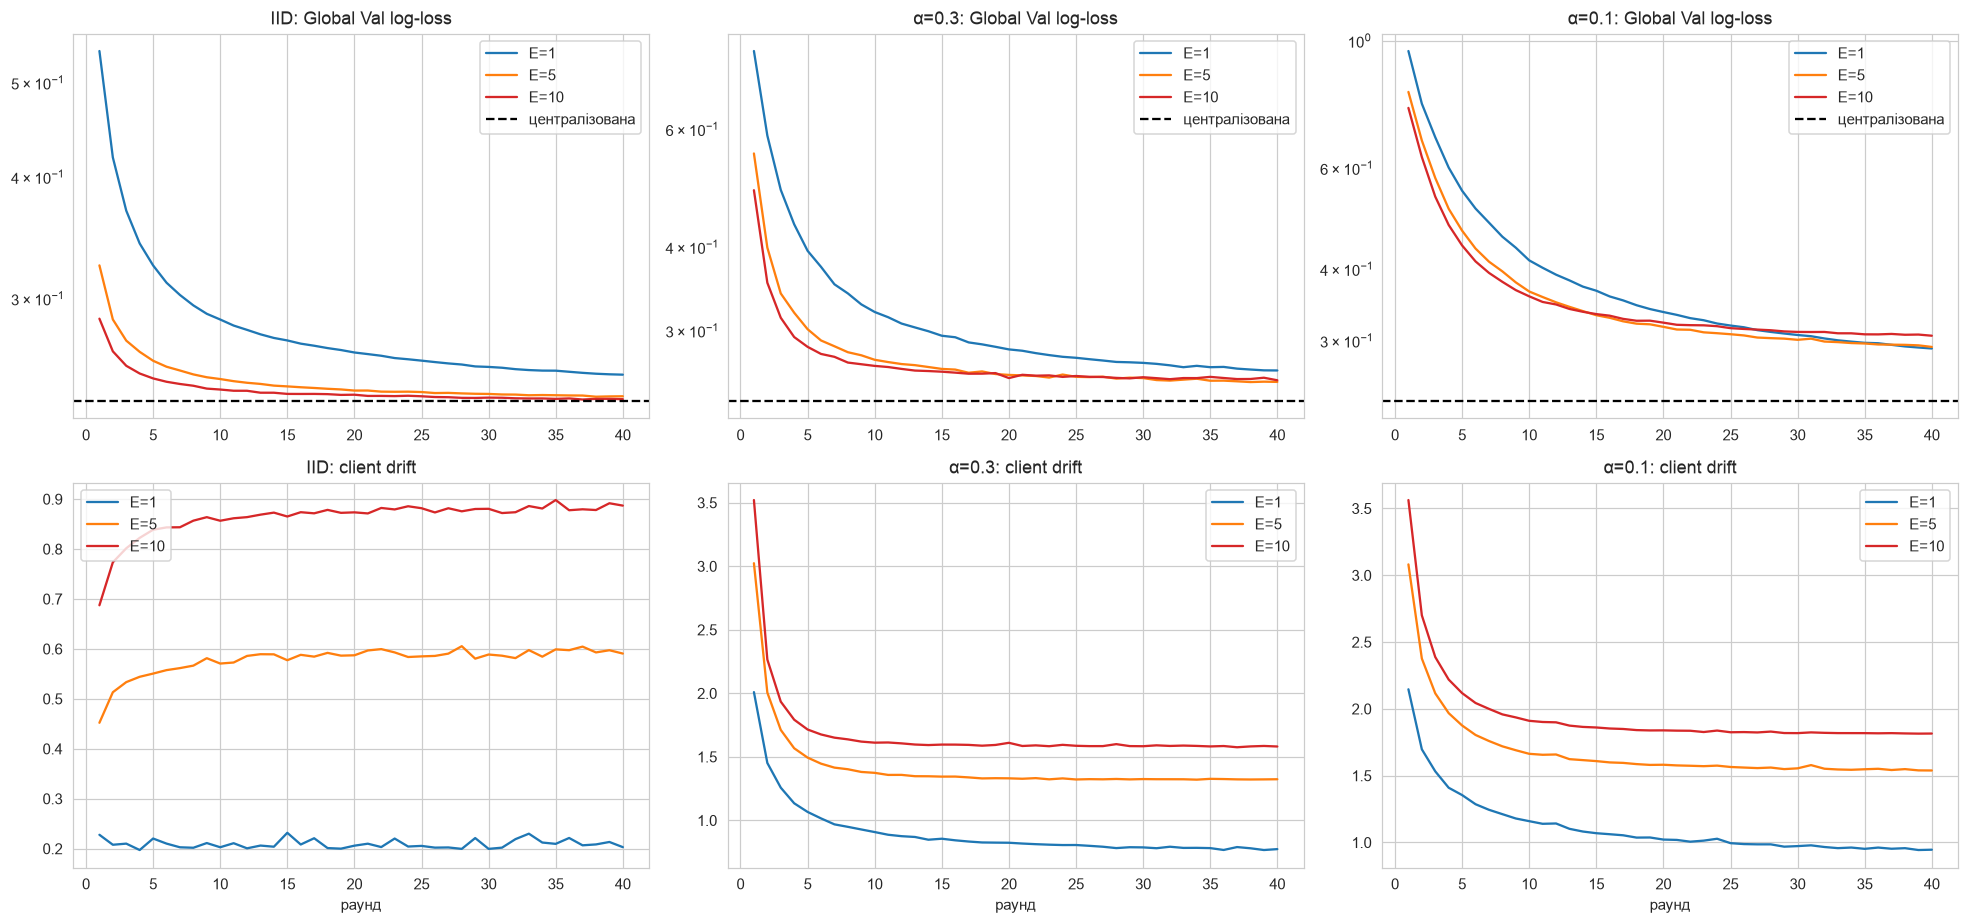

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8.5))
for j, a in enumerate(SCEN):
    for E, c in zip(E_GRID, ['tab:blue', 'tab:orange', 'tab:red']):
        vl = np.mean([exp2_hist[(a, E, s)]['val_loss'] for s in SEEDS], axis=0)
        dr = np.mean([exp2_hist[(a, E, s)]['drift'] for s in SEEDS], axis=0)
        axes[0, j].plot(range(1, ROUNDS + 1), vl, c=c, label=f'E={E}')
        axes[1, j].plot(range(1, ROUNDS + 1), dr, c=c, label=f'E={E}')
    axes[0, j].axhline(c_val['log-loss'], c='k', ls='--', label='централізована')
    axes[0, j].set_title(f'{"IID" if a == "IID" else "α=" + str(a)}: Global Val log-loss'); axes[0, j].set_yscale('log')
    axes[1, j].set_title(f'{"IID" if a == "IID" else "α=" + str(a)}: client drift'); axes[1, j].set_xlabel('раунд')
    axes[0, j].legend(); axes[1, j].legend()
plt.tight_layout(); plt.show()

**Що показано:** val log-loss і client drift за раундами для E = 1, 5, 10 та фінальні метрики на Test (середнє за 3 seed).

**Закономірність:**
* **IID:** більше E — однозначно краще. Швидша збіжність (log-loss після 40 раундів: 0.242 → 0.231 → 0.230), а фінальна
  accuracy 0.916 → 0.917 → 0.918. Drift росте з E (0.21 → 0.58 → 0.86), але це лише шум SGD — він не шкодить.
* **α = 0.3:** E = 5 найкращий (0.913). При E = 10 якість уже трохи гірша (0.911, log-loss 0.2447 vs 0.2435) — оптимум
  посередині.
* **α = 0.1:** на старті E = 10 найшвидший (найнижча крива в перші ~20 раундів). Далі криві перетинаються: E = 10 виходить
  на *вище* плато. Фінал: accuracy 0.895 проти 0.903 при E = 1, log-loss 0.301 проти 0.282. Drift при E = 10 найбільший (1.95).

**Client drift** — явище, коли за $E$ локальних епох модель клієнта відходить від глобальної в бік локального мінімуму
$w_k^*$ і «переналаштовується» на свій перекошений розподіл. Що більше $E$, то ближче $w_k$ до $w_k^*$ і далі від спільного оптимуму.

**Чому велика E погіршує модель у Non-IID.** При $E=1$ і малому lr FedAvg ≈ звичайний SGD по глобальній функції: локальні
кроки малі, тож їхнє середнє ≈ глобальний градієнт. При великому $E$ сервер фактично усереднює *різні локальні оптимуми*.
Точка, до якої збігається такий процес, не збігається з мінімумом глобальної функції — це систематичне зміщення, яке не зникає
з раундами. Тому бачимо характерну картину:
* великий E швидше стартує (більше обчислень за раунд, менше комунікацій);
* але виходить на гірше плато (drift).

**Практичний висновок:** E — компроміс між вартістю комунікації (менше раундів) і якістю. Для IID можна брати велике E.
Для сильного Non-IID — помірне ($E \approx 1–5$), зменшувати lr з раундами або використовувати методи з корекцією drift
(FedProx, SCAFFOLD).

### 6.4 Зважена vs проста агрегація (відповідь на питання Етапу 5)

Порівнюємо FedAvg зі зважуванням $n_k/\sum n_j$ і з простим середнім на розподілах, де $n_k$ сильно різняться.

In [32]:
w_rows = []
for a in [1, 0.3, 0.1]:
    for s in SEEDS:
        parts = dirichlet_partition(y_pool, K, alpha=a, seed=s, min_size=MIN_SIZE)[0]
        nk = np.array([len(p) for p in parts])
        for wmode in ['n_k', 'uniform']:
            srv = run_fedavg(make_clients(parts, X_pool, y_pool, seed=s), ROUNDS, E_BASE, weighting=wmode, seed=s)
            g = srv.evaluate_test()
            w_rows.append({'α': a, 'seed': s, 'агрегація': 'зважена (FedAvg)' if wmode == 'n_k' else 'просте середнє',
                           'max n_k / min n_k': nk.max() / nk.min(), 'test acc': g['accuracy'],
                           'test macro-F1': g['macro-F1'], 'test log-loss': g['log-loss']})
wtab = pd.DataFrame(w_rows)
display(wtab.drop(columns='seed').groupby(['α', 'агрегація']).mean().round(4))

max n_k / min n_k  test acc  test macro-F1  \
α   агрегація                                                      
0.1 зважена (FedAvg)            22.8302    0.9026         0.9140   
    просте середнє              22.8302    0.9075         0.9206   
0.3 зважена (FedAvg)            12.5544    0.9131         0.9254   
    просте середнє              12.5544    0.9119         0.9254   
1.0 зважена (FedAvg)             2.8949    0.9160         0.9281   
    просте середнє               2.8949    0.9147         0.9276   

                      test log-loss  
α   агрегація                        
0.1 зважена (FedAvg)         0.2863  
    просте середнє           0.2652  
0.3 зважена (FedAvg)         0.2435  
    просте середнє           0.2405  
1.0 зважена (FedAvg)         0.2306  
    просте середнє           0.2339

**Результат (середнє за 3 seed):**

| α | співвідношення max/min $n_k$ | FedAvg (зважена) acc / macro-F1 | Просте середнє acc / macro-F1 |
|---|---|---|---|
| 1 | ~2.9 | 0.916 / 0.928 | 0.915 / 0.928 |
| 0.3 | ~12.6 | 0.913 / 0.925 | 0.912 / 0.925 |
| 0.1 | ~22.8 | 0.903 / 0.914 | **0.908 / 0.921** |

**Чому зважувати за $n_k$ (теорія).** Централізована функція втрат — це середнє по *всіх прикладах*:
$J(w)=\frac1N\sum_{i}\ell_i = \sum_k \frac{n_k}{N}J_k(w)$. Отже, зважене середнє локальних градієнтів/моделей з вагами
$n_k/N$ є незміщеною оцінкою кроку по глобальній функції. Кожен *приклад* має однаковий вплив, як у централізованому навчанні.

**Що буде без зважування.** Кожен *клієнт* має однаковий вплив, тож приклади маленьких клієнтів «важать» більше. Наслідки:
* якщо малий клієнт має шумні чи нерепрезентативні дані, він непропорційно псує модель;
* модель оптимізує іншу ціль — середню якість «по клієнтах», а не «по прикладах».

**Що показав експеримент.** При α ≤ 1 різниця в межах шуму. Але при α = 0.1 просте середнє навіть трохи краще:
macro-F1 0.921 проти 0.914, log-loss 0.265 проти 0.286. Причина — перекіс класів *корелює* з розміром клієнта.
Найбільші клієнти здебільшого мають частий DERMASON та SIRA, тож зважування за $n_k$ посилює домінування великих класів.
Просте середнє дає більше голосу маленьким клієнтам із рідкісними класами, і macro-метрики покращуються.

Отже, зважування за $n_k$ правильне для цілі «мінімізувати середню помилку по всіх прикладах». Воно не є універсально
найкращим, коли розмір клієнта пов'язаний з перекосом міток. Для справедливості між клієнтами/класами існують альтернативи
(q-FFL, агрегація з поправкою на розподіл класів).

## Етап 7 (опційно). Додаткові експерименти

### Експеримент А. Вплив кількості клієнтів K

середній n_k  global acc  global macro-F1  local acc (середнє)
сценарій K                                                                 
IID      3      3159.6667      0.9173           0.9296               0.9156
         5      1895.8000      0.9167           0.9286               0.9143
         10      947.9000      0.9162           0.9284               0.9111
1        3      3159.6667      0.9154           0.9279               0.8634
         5      1895.8000      0.9160           0.9281               0.8712
         10      947.9000      0.9158           0.9282               0.8552
0.3      3      3159.6667      0.9122           0.9263               0.7581
         5      1895.8000      0.9131           0.9254               0.6900
         10      947.9000      0.9132           0.9253               0.6567

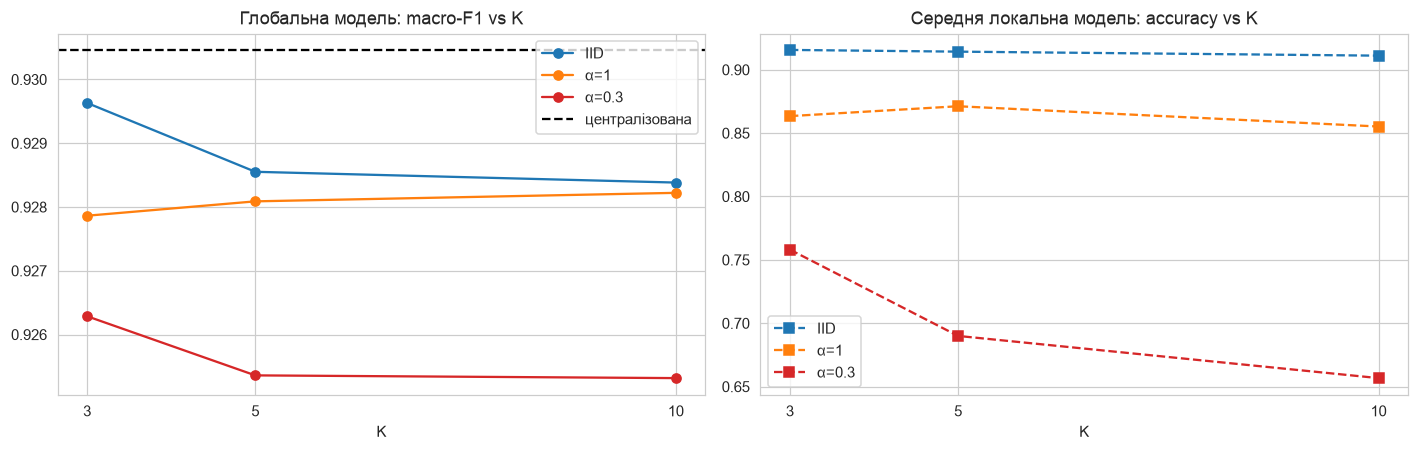

In [33]:
K_GRID = [3, 5, 10]
ka_rows = []
for a in ['IID', 1, 0.3]:
    for Kx in K_GRID:
        for s in SEEDS:
            parts = iid_partition(y_pool, Kx, seed=s) if a == 'IID' else dirichlet_partition(y_pool, Kx, alpha=a, seed=s, min_size=MIN_SIZE)[0]
            srv = run_fedavg(make_clients(parts, X_pool, y_pool, seed=s), ROUNDS, E_BASE, seed=s)
            g = srv.evaluate_test()
            loc_acc = [evaluate(c.train_local_only(EPOCHS_C, LR, BS, LAM), X_test, y_test)['accuracy']
                       for c in make_clients(parts, X_pool, y_pool, seed=s)]
            ka_rows.append({'сценарій': str(a), 'K': Kx, 'seed': s, 'середній n_k': np.mean([len(p) for p in parts]),
                            'global acc': g['accuracy'], 'global macro-F1': g['macro-F1'],
                            'local acc (середнє)': np.mean(loc_acc)})
ka = pd.DataFrame(ka_rows).drop(columns='seed').groupby(['сценарій', 'K'], sort=False).mean()
display(ka.round(4))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a, c in zip(['IID', '1', '0.3'], ['tab:blue', 'tab:orange', 'tab:red']):
    sub = ka.loc[a]
    ax[0].plot(K_GRID, sub['global macro-F1'], 'o-', c=c, label=f'{"IID" if a == "IID" else "α=" + a}')
    ax[1].plot(K_GRID, sub['local acc (середнє)'], 's--', c=c, label=f'{"IID" if a == "IID" else "α=" + a}')
ax[0].axhline(central_test['macro-F1'], c='k', ls='--', label='централізована')
ax[0].set_title('Глобальна модель: macro-F1 vs K'); ax[1].set_title('Середня локальна модель: accuracy vs K')
for a_ in ax: a_.set_xlabel('K'); a_.set_xticks(K_GRID); a_.legend()
plt.tight_layout(); plt.show()

**Що показано:** якість глобальної та середньої локальної моделі при K = 3, 5, 10 (той самий FL Train Pool, 3 seed).

**Закономірність:**
* Глобальна модель майже не залежить від K: усі значення macro-F1 у діапазоні 0.925–0.930. Різниця між K = 3 і K = 10
  ≤ 0.1 п.п., що порівнянно з розкидом між seed.
* Середня локальна модель погіршується зі зростанням K, особливо у Non-IID: при α = 0.3 accuracy падає з 0.758 до 0.657.

**Чому:**
* Більше клієнтів — у кожного менше даних (середній $n_k$: 3160 → 948), і при Non-IID кожен бачить вужчу частину класів.
  Тому окремому клієнту самотужки навчитися стає важче.
* Глобальна модель агрегує всі ті самі дані. Для опуклої моделі з 77 параметрами збільшення кількості учасників з тим самим
  сумарним обсягом майже не змінює досяжний результат.
* Ціна більшого K проявилася б у реальній системі (більше комунікацій, часткова участь, «повільні» клієнти), а не в точності
  цієї симуляції.

**Висновок:** що більше клієнтів із малими даними, то *більшою* стає користь від FL порівняно з локальним навчанням
(розрив global − local зростає з 15 до 26 п.п. при α = 0.3).

### Експеримент Б. Персоналізація (fine-tuning глобальної моделі)

Сильно неоднорідний сценарій α = 0.3. Кожен клієнт **локально** ділить свою $D_k$ на local-train (80 %) і local-test (20 %);
FedAvg навчається лише на local-train частинах. Потім кожен клієнт донавчає глобальну модель **2 епохи** на своєму
local-train. Порівнюємо на local-test кожного клієнта: суто локальну, глобальну та персоналізовану моделі.

In [34]:
def personalization_experiment(alpha=0.3, seed=0, ft_epochs=2):
    parts = dirichlet_partition(y_pool, K, alpha=alpha, seed=seed, min_size=MIN_SIZE)[0]
    rng = np.random.default_rng(seed)
    tr_parts, te_parts = [], []
    for p in parts:
        p = rng.permutation(p); cut = int(0.8 * len(p))
        tr_parts.append(p[:cut]); te_parts.append(p[cut:])
    srv = run_fedavg(make_clients(tr_parts, X_pool, y_pool, seed=seed), ROUNDS, E_BASE, seed=seed)
    rows = []
    for k, (ptr, pte) in enumerate(zip(tr_parts, te_parts)):
        Xtr, ytr, Xte, yte = X_pool[ptr], y_pool[ptr], X_pool[pte], y_pool[pte]
        local = SoftmaxRegression(Xtr.shape[1], C, lam=LAM, seed=k).fit(Xtr, ytr, EPOCHS_C, BS, LR, record=False)
        pers = SoftmaxRegression(Xtr.shape[1], C, lam=LAM, seed=k); pers.set_params(srv.model.get_params())
        pers.fit(Xtr, ytr, ft_epochs, BS, LR, record=False)
        rows.append({'client': k, 'n local-train': len(ptr), 'n local-test': len(pte),
                     'класів у клієнта': len(np.unique(ytr)),
                     'acc: локальна': (local.predict(Xte) == yte).mean(),
                     'acc: глобальна': (srv.model.predict(Xte) == yte).mean(),
                     'acc: персоналізована': (pers.predict(Xte) == yte).mean(),
                     'global Test acc: глобальна': srv.evaluate_test()['accuracy'],
                     'global Test acc: персоналізована': evaluate(pers, X_test, y_test)['accuracy']})
    return pd.DataFrame(rows).set_index('client')

pers_tabs = [personalization_experiment(0.3, s) for s in SEEDS]
print('Seed 0 — по клієнтах:'); display(pers_tabs[0].round(4))
summary = pd.DataFrame({f'seed {s}': t[['acc: локальна', 'acc: глобальна', 'acc: персоналізована',
                                        'global Test acc: глобальна', 'global Test acc: персоналізована']].mean()
                        for s, t in zip(SEEDS, pers_tabs)})
summary['середнє'] = summary.mean(axis=1)
print('Середнє по клієнтах (local-test кожного клієнта + Global Test):'); display(summary.round(4))

Seed 0 — по клієнтах:


,n local-train,n local-test,класів у клієнта,acc: локальна,acc: глобальна,acc: персоналізована,global Test acc: глобальна,global Test acc: персоналізована
client,,,,,,,,
0,2928,732,6,0.9672,0.9385,0.9686,0.9149,0.8942
1,1480,370,6,0.9595,0.9162,0.9730,0.9149,0.8765
2,1542,386,6,0.9819,0.8938,0.9793,0.9149,0.8022
3,1121,281,6,0.9715,0.9786,0.9751,0.9149,0.9045
4,511,128,7,0.9766,0.9297,0.9688,0.9149,0.8612


Середнє по клієнтах (local-test кожного клієнта + Global Test):


,seed 0,seed 1,seed 2,середнє
acc: локальна,0.9713,0.9598,0.9517,0.9609
acc: глобальна,0.9314,0.9117,0.9184,0.9205
acc: персоналізована,0.9729,0.9667,0.9345,0.9581
global Test acc: глобальна,0.9149,0.9090,0.9114,0.9117
global Test acc: персоналізована,0.8677,0.8586,0.8889,0.8717


**Що показано:** якість на **local-test** кожного клієнта (його власний розподіл) та на Global Test для трьох моделей:
суто локальної, глобальної FedAvg і персоналізованої (глобальна + 2 локальні епохи). α = 0.3, 3 seed.

**Закономірність (середнє за клієнтами і seed):**
* На local-test: локальна **0.961**, глобальна **0.921**, персоналізована **0.958**.
* На Global Test: глобальна **0.912**, персоналізована **0.872**.

**Чому:**
* Local-test має той самий перекошений розподіл класів, що й дані клієнта. Клієнт, у якого 90 % HOROZ, отримує величезний
  виграш, якщо модель «знає» цей апріорний розподіл. Глобальна модель налаштована на *загальний* розподіл і для конкретного
  клієнта не оптимальна.
* Персоналізація за 2 епохи зсуває модель (передусім зсуви $b$) під локальний розподіл і майже повністю закриває розрив до
  локальної моделі.
* Ціна — погіршення на глобальному розподілі (−4 п.п.). Це той самий client drift, але тепер він *бажаний*, бо ціль — якість для
  конкретного клієнта.

**Висновок:**
* Якщо модель має працювати на даних *цього* клієнта з його розподілом, персоналізація корисна.
* Якщо клієнту важливо розпізнавати всі класи, наприклад майбутні нові сорти, кращою є глобальна модель.

У нашому випадку суто локальні моделі на своїх local-test не гірші за персоналізовані: у кожного клієнта ~500–3000 прикладів,
а задача проста. Перевага персоналізації була б більшою для клієнтів з дуже малими даними, де суто локальна модель перенавчається.

## Завдання з лекційного ноутбука (machine_learning_2.ipynb)

У лекції «Polynomial Regression. Model Complexity. Regularisation. Logistic Regression» у розділі *Practical Insights
for Logistic Regression* є два завдання для практичної роботи.

### Завдання 1. Якщо $p = 1$, отримуємо ділення на нуль. Пояснити проблему.

Шанси (odds) визначаються як $\dfrac{p}{1-p}$, а log-odds як $\ln\dfrac{p}{1-p} = z = \mathbf w^\top\mathbf x + b$.
При $p = 1$ знаменник $1-p = 0$: шанси дорівнюють $+\infty$, log-odds — теж $+\infty$.

**Чому так виходить математично.** Сигмоїда $p = \dfrac{1}{1+e^{-z}}$ при будь-якому скінченному $z$ дає $p<1$.
Рівність $p=1$ можлива лише при $z=+\infty$, тобто при нескінченних вагах. Отже, $p=1$ означає абсолютну впевненість,
яку модель зі скінченними параметрами не може виразити, і log-odds для неї не визначені.

**Чому це стається на практиці.** Числа з плаваючою комою мають обмежену точність. У `float64` вже при $z \gtrsim 37$
вираз $1+e^{-z}$ округлюється рівно до $1$, тож комп'ютер повертає `p == 1.0` (див. код нижче). Тоді:
* $\dfrac{p}{1-p}$ — ділення на нуль (`inf`), $\ln\dfrac{p}{1-p}$ — `inf`;
* у функції втрат для прикладу з $y=0$ з'являється $\log(1-p) = \log 0 = -\infty$, тож loss і градієнти стають `inf`/`nan`
  і навчання ламається.

**Коли до цього доходить.** Коли дані лінійно роздільні: без регуляризації ваги ростуть необмежено, бо так втрати
весь час трохи зменшуються, і $p\to1$. У нашій роботі клас BOMBAY майже лінійно відокремлюється за площею, і без Ridge
його ваги найбільші.

**Як це вирішується (і як зроблено в нашому коді):**
1. **Обрізання ймовірностей (clipping):** у `loss` ми рахуємо `np.log(np.clip(P, 1e-15, 1.0))`, тож $\log 0$ неможливий.
   `sklearn.metrics.log_loss` робить так само.
2. **Обчислення в просторі логітів:** у `softmax` віднімаємо максимум рядка, тож експонента не переповнюється.
   Log-odds беремо безпосередньо як $z$ (або $Z_c - Z_k$), а не через $\ln\frac{p}{1-p}$.
3. **Регуляризація (Ridge):** штраф $\frac\lambda2\lVert W\rVert^2$ не дає вагам рости до нескінченності, тож $p$ лишається $<1$.

In [35]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

for z in [5, 20, 36, 37, 40]:
    p = sigmoid(z)
    with np.errstate(divide='ignore'):
        odds = p / (1 - p)
    print(f'z = {z:3d}:  p = {p:.17f}   p == 1.0: {str(p == 1.0):5}   odds = p/(1-p) = {odds:.4g}   (точно e^z = {np.exp(z):.4g})')

print('\nНаша функція втрат залишається скінченною навіть при P = 1 для неправильного класу:')
m_demo = SoftmaxRegression(1, 2)
m_demo.W = np.array([[50.0, -50.0]])           # величезні ваги -> P ≈ [1, 0]
print('P =', m_demo.predict_proba(np.array([[1.0]])).round(6),
      '  loss для правильного класу 1:', round(m_demo.loss(np.array([[1.0]]), np.array([[0.0, 1.0]])), 3), '(= -ln(1e-15))')

z =   5:  p = 0.99330714907571527   p == 1.0: False   odds = p/(1-p) = 148.4   (точно e^z = 148.4)
z =  20:  p = 0.99999999793884631   p == 1.0: False   odds = p/(1-p) = 4.852e+08   (точно e^z = 4.852e+08)
z =  36:  p = 0.99999999999999978   p == 1.0: False   odds = p/(1-p) = 4.504e+15   (точно e^z = 4.311e+15)
z =  37:  p = 1.00000000000000000   p == 1.0: True    odds = p/(1-p) = inf   (точно e^z = 1.172e+16)
z =  40:  p = 1.00000000000000000   p == 1.0: True    odds = p/(1-p) = inf   (точно e^z = 2.354e+17)

Наша функція втрат залишається скінченною навіть при P = 1 для неправильного класу:
P = [[1. 0.]]   loss для правильного класу 1: 34.539 (= -ln(1e-15))


### Завдання 2. Довести, що Odds Ratio $= e^{w_j}$

**Дано:** $p = \sigma(z) = \dfrac{1}{1+e^{-z}}$, де $z = \mathbf w^\top\mathbf x + b = w_1x_1 + \dots + w_jx_j + \dots + w_dx_d + b$.

**Крок 1. Шанси через $z$.**
$$1-p = 1 - \frac{1}{1+e^{-z}} = \frac{e^{-z}}{1+e^{-z}}\quad\Rightarrow\quad
\text{odds}(\mathbf x) = \frac{p}{1-p} = \frac{1}{e^{-z}} = e^{z} = e^{\mathbf w^\top\mathbf x + b}.$$

**Крок 2. Збільшуємо одну ознаку на 1.** Нехай $\mathbf x'$ відрізняється від $\mathbf x$ лише тим, що $x_j' = x_j + 1$
(усі інші ознаки сталі). Тоді
$$z' = \mathbf w^\top\mathbf x' + b = \mathbf w^\top\mathbf x + b + w_j = z + w_j .$$

**Крок 3. Відношення шансів.**
$$\text{Odds Ratio} = \frac{\text{odds}(\mathbf x')}{\text{odds}(\mathbf x)} = \frac{e^{z + w_j}}{e^{z}} = e^{w_j}.\qquad\blacksquare$$

**Висновок.** Відношення шансів не залежить ні від $\mathbf x$, ні від $b$, ні від інших ваг. Збільшення $x_j$ на одиницю
завжди *множить* шанси на одне й те саме число $e^{w_j}$:
* $w_j>0$ → шанси ростуть, $w_j<0$ → падають, $w_j=0$ → ознака не впливає;
* приклад з лекції: $w=0.69$ → $e^{0.69}\approx2$ (шанси подвоюються).

Еквівалентно, логістична регресія — це лінійна модель для log-odds: $\ln\frac{p}{1-p} = \mathbf w^\top\mathbf x + b$.

**Узагальнення на softmax (наша модель).** Для двох класів $c$ і $k$:
$$\frac{P_c}{P_k} = \frac{e^{Z_c}/\sum_j e^{Z_j}}{e^{Z_k}/\sum_j e^{Z_j}} = e^{Z_c - Z_k},\qquad Z_c - Z_k = \mathbf x^\top(W_{:,c}-W_{:,k}) + (b_c - b_k).$$
Тому при $x_j \to x_j + 1$ відношення шансів класу $c$ проти класу $k$ множиться на $e^{W_{jc}-W_{jk}}$ — той самий
доказ, лише замість однієї ваги різниця двох ваг. У нас ознаки стандартизовані, тож «+1» означає «+1 стандартне відхилення».
Перевіримо це чисельно на централізованій моделі.

In [36]:
j, c, k = FEATURES.index('Area'), cls2id['BOMBAY'], cls2id['DERMASON']
x = X_test[:5].copy()                      # кілька довільних зерен з тесту
x_plus = x.copy(); x_plus[:, j] += 1.0     # +1 (стандартне відхилення) до Area, решта без змін

P, P_plus = central.predict_proba(x), central.predict_proba(x_plus)
empirical = (P_plus[:, c] / P_plus[:, k]) / (P[:, c] / P[:, k])
theory = np.exp(central.W[j, c] - central.W[j, k])
print('Ознака Area, шанси BOMBAY проти DERMASON:')
print('  емпіричне відношення шансів для 5 різних зерен:', np.round(empirical, 4))
print(f'  теорія e^(W_jc − W_jk) = {theory:.4f}  → однакове для всіх зерен, як і доводили')

Ознака Area, шанси BOMBAY проти DERMASON:
  емпіричне відношення шансів для 5 різних зерен: [5886.3048 5886.3048 5886.3048 5886.3048 5886.3048]
  теорія e^(W_jc − W_jk) = 5886.3048  → однакове для всіх зерен, як і доводили


## Відповіді на теоретичні питання

**1. Чому для багатокласової класифікації використовують softmax?**
Логіти $Z_{ic}\in(-\infty,+\infty)$ треба перетворити на розподіл ймовірностей: кожне $P_{ic}\in(0,1)$, а сума по класах дорівнює 1.
Softmax робить саме це, зберігаючи порядок логітів (найбільший логіт → найбільша ймовірність). Він диференційовний і є природним
узагальненням сигмоїди: при $C=2$ softmax зводиться до $\sigma(z_1-z_2)$. Статистично softmax відповідає моделі, у якій
логарифми відношень шансів між класами лінійні за ознаками (мультиноміальна логістична регресія, GLM з категоріальним розподілом).

**2. Чому крос-ентропія — природна функція втрат для логістичної регресії?**
* **Статистично:** це від'ємна логарифмічна правдоподібність категоріального розподілу. Мінімізація крос-ентропії = метод
  максимальної правдоподібності.
* **Оптимізаційно:** у поєднанні з softmax вона дає *опуклу* функцію за $W,b$ (єдиний глобальний мінімум) і дуже простий
  градієнт $X^\top(P-Y)/m$.
* **На противагу MSE:** MSE з softmax/сигмоїдою неопукла, а її градієнт майже зникає, коли модель впевнено помиляється
  (насичення). Крос-ентропія ж сильно карає впевнені помилки ($-\log P\to\infty$ при $P\to0$).

**3. Чим Ridge відрізняється від Lasso?**
Ridge (L2) додає $\frac\lambda2\sum w^2$, Lasso (L1) — $\lambda\sum|w|$.
* Ridge плавно зменшує всі ваги пропорційно їхній величині, але майже ніколи не робить їх рівно нулем. Функція гладка, і при
  корельованих ознаках Ridge «ділить» вагу між ними.
* Lasso має недиференційовну точку в 0, тож багато ваг стають *рівно* нулем. Це вбудований відбір ознак, розріджена модель.
  При групі корельованих ознак Lasso зазвичай залишає одну з них.
* Геометрично: обмеження L2 — куля, L1 — ромб/кросполітоп із «кутами» на осях, і оптимум часто потрапляє саме в такий кут.

**4. Чому зсув $b$ зазвичай не регуляризують?**
$b$ не відповідає за складність чи «звивистість» межі — він лише зсуває її і кодує апріорні частоти класів. Штраф на $b$
змушував би модель вважати класи рівноймовірними і систематично зміщував би прогнози (особливо при дисбалансі), не зменшуючи
перенавчання. До того ж регуляризація $b$ робила б модель залежною від зсуву цілі/ознак.

**5. Що таке Data Leakage?**
Потрапляння в процес навчання (включно з попередньою обробкою і вибором гіперпараметрів) інформації, яка недоступна в момент
реального прогнозу — насамперед з валідаційних/тестових даних або з цілі. Приклади:
* масштабування на всьому датасеті;
* дублікати, що потрапили і в Train, і в Test;
* target encoding без out-of-fold;
* у FL — використання клієнтами Global Test.

Наслідок — завищена оцінка якості.

**6. Чому тестову вибірку не можна використовувати для підбору гіперпараметрів?**
Вибір гіперпараметрів — теж навчання: ми обираємо ту конфігурацію, яка найкраще працює *на цих конкретних даних*. Якщо це
тестові дані, модель опосередковано підлаштовується під них, і оцінка на Test стає оптимістично зміщеною (особливо при багатьох
перебраних варіантах). Тоді в нас не лишається незалежної оцінки якості на нових даних. Тому є окрема Validation, а Test
використовується один раз наприкінці.

**7. Чому параметри масштабування треба навчати лише на тренувальних даних?**
$\mu$ і $\sigma$ — це оцінені з даних параметри, так само як ваги моделі. Якщо включити Test, у перетворення потрапить інформація
про тестовий розподіл (leakage). Крім того, в реальному застосуванні нові об'єкти приходять по одному, і «статистик майбутніх
даних» просто немає. У FL додатково: статистики агрегуються лише з клієнтських тренувальних даних (підхід (б) у цій роботі),
а сервер застосовує їх до Validation/Test.

**8. Що таке федеративне навчання і які його переваги?**
Розподілене навчання, у якому дані залишаються в клієнтів, а назовні передаються лише параметри або їхні оновлення. Сервер
лише координує раунди та агрегує моделі (FedAvg). Переваги:
* **приватність і відповідність законодавству** (GDPR, медичні й фінансові дані) — сирі дані не покидають власника;
* **можливість навчатися на даних**, які неможливо зібрати разом (комерційна таємниця, обсяг, мобільні пристрої);
* **менший мережевий трафік** — модель зазвичай значно менша за дані;
* **краща модель, ніж у кожного учасника окремо** (у нас: 0.914 проти 0.78–0.89 у локальних при α = 1).

**9. Чому сервер не повинен отримувати сирі дані клієнтів?**
Це і є суть FL: захист приватності, конфіденційності та права власності на дані. Сервер може бути скомпрометований, мати
інші інтереси або підпадати під інше законодавство. Передача сирих даних створює єдину точку витоку й часто просто заборонена
(медицина, банки). Навіть параметри можуть частково розкривати дані (membership inference), тому на практиці FL поєднують із
secure aggregation та диференційною приватністю.

**10. Чому FedAvg зважує клієнтів за кількістю прикладів?**
Бо глобальна ціль — середня втрата по *всіх прикладах*: $J(w)=\sum_k \frac{n_k}{N}J_k(w)$. Зважене середнє локальних оновлень
з вагами $n_k/N$ відповідає кроку по цій функції, тобто відтворює централізоване навчання. Крім того, модель клієнта з більшими
даними — точніша (менша дисперсія) оцінка, і їй справедливо довіряти більше.

**11. Що станеться при агрегації без зважування?**
Кожен клієнт матиме однаковий голос незалежно від обсягу даних. Приклади малих клієнтів матимуть непропорційно великий вплив,
модель оптимізуватиме іншу ціль (середнє «по клієнтах»), а шумні малі клієнти можуть погіршити модель. В IID з рівними $n_k$
різниці немає. У нашому експерименті при α ≤ 1 різниця в межах шуму, а при α = 0.1 просте середнє навіть трохи покращило
macro-F1: великі клієнти мали переважно великі класи. Тож наслідки залежать від того, як розмір клієнта пов'язаний із його
розподілом (див. розділ 6.4).

**12. Що таке Non-IID дані?**
Дані, які між клієнтами розподілені *не* незалежно й *не* однаково: $P_k(x,y)\ne P_j(x,y)$. Типи:
* перекіс міток ($P_k(y)$ різні — наш випадок із Діріхле);
* перекіс ознак (різні камери → різна яскравість, масштаб);
* однакові мітки, але різні ознаки для них (concept shift);
* різні обсяги даних;
* часова неоднорідність.

У реальних FL-системах Non-IID — норма, а не виняток.

**13. Чому FL може погіршуватися на Non-IID даних?**
Локальні функції втрат мають різні мінімуми, тож:
* локальні градієнти не є незміщеними оцінками глобального;
* після кількох локальних кроків моделі розходяться (client drift), і їхнє середнє — не мінімум глобальної функції;
* рідкісні класи, наявні лише в кількох клієнтів, «розбавляються» при усередненні.

Результат — повільніша збіжність, коливання між раундами і гірша фінальна якість (у нас 0.918 → 0.903 при α → 0.1).

**14. Що таке client drift?**
Відхилення локальних моделей від глобальної (і від глобального оптимуму) під час локального навчання. Кожен клієнт рухається
до мінімуму своєї $J_k$. При Non-IID ці мінімуми різні, тож локальні моделі «розповзаються», і агрегація дає зміщену модель.
Ми вимірювали drift як $\lVert W_k - W_{global}\rVert_F$: він росте і з неоднорідністю (0.59 → 1.54), і з кількістю локальних
епох (1.11 → 1.95 при α = 0.1).

**15. Як кількість локальних епох впливає на глобальну модель?**
* Більше $E$ — більше обчислень між комунікаціями, тож потрібно менше раундів (дешевше за трафіком).
* У IID це майже безкоштовно (у нас E = 10 найкращий).
* У Non-IID велике $E$ збільшує client drift: модель швидше стартує, але виходить на гірше плато (при α = 0.1: E = 10 дає
  0.895 проти 0.903 при E = 1).

Оптимальне $E$ — компроміс, який залежить від неоднорідності.

**16. Чи може глобальна модель бути гіршою за централізовану? Чому?**
Так, і зазвичай так і є, хоча в IID розрив мізерний. Централізована модель оптимізує глобальну функцію безпосередньо, а FedAvg —
через усереднення локальних моделей, що при Non-IID дає зміщення й повільнішу збіжність. Додатково — обмежена кількість раундів,
часткова участь клієнтів, різний обсяг даних. У нас: 0.918 (централізована) проти 0.917 (IID) і 0.903 (α = 0.1). При IID, малому
lr та E = 1 FedAvg математично наближається до централізованого SGD.

**17. Які метрики краще використовувати для багатокласової класифікації з дисбалансом класів?**
Accuracy при дисбалансі домінують великі класи: модель, що ігнорує рідкісний клас, усе одно може мати високу accuracy. Краще:
* **macro-F1** — F1 кожного класу усереднюється з однаковою вагою;
* **balanced accuracy** — середній recall по класах;
* **confusion matrix** — показує, *які саме* класи плутаються;
* **per-class precision/recall/F1**;
* **log-loss** — якість ймовірностей (калібровка).

Для рідкісних класів також корисні PR-криві / average precision. У нашій роботі основні метрики — macro-F1 і balanced accuracy,
а accuracy наведено для довідки.

## Загальний висновок

1. **Дані та підготовка.**
   * Dry Bean (7 класів, 13.5 тис. прикладів) підходить для FL: багато прикладів, дисбаланс класів, природний сценарій
     «різні господарства — різні сорти».
   * Дублікати видалено до розбиття.
   * Стратифіковане розбиття: Global Test 15 % / Global Validation 15 % / FL Train Pool 70 %.
   * Відбір ознак на Pool: 10 з 16 без втрати якості, з кращою обумовленістю.
   * Масштабування — федеративним способом (б): клієнти передають лише $(n_k,\mu_k,\sigma_k^2)$. Результат математично
     збігається з пулом (похибка ~$10^{-13}$).
2. **Модель.** Softmax-регресію з крос-ентропією та Ridge реалізовано на numpy, векторизовано. Градієнт перевірено чисельно
   (похибка ~$10^{-9}$). Значення функції втрат збігається з `sklearn.LogisticRegression`, а наш градієнт у точці оптимуму
   sklearn дорівнює нулю.
3. **Централізований baseline** (lr = 0.3, B = 32, λ = 0): Global Test accuracy 0.918, macro-F1 0.931, balanced accuracy 0.931,
   log-loss 0.229. Основна плутанина — DERMASON ↔ SIRA. Ridge не допоміг: модель проста, даних багато, тобто перенавчання
   немає, а великий λ спричиняє недонавчання.
4. **Розподіл між клієнтами** реалізовано з гарантією «кожен приклад — рівно в одного клієнта». Він відтворюваний (фіксований seed)
   і задокументований таблицями та тепловими картами. Архітектура в коді розділяє доступ: `Client` бачить лише свої дані,
   `Server` — лише Validation/Test і параметри.
5. **FedAvg** при IID і помірній неоднорідності майже досягає централізованої якості (0.914–0.918) і стабільно перевершує кожну
   локальну модель на Global Test. Користь FL зростає з неоднорідністю та кількістю клієнтів: при α = 0.3 середня локальна модель
   має лише 0.69, а глобальна — 0.913.
6. **Неоднорідність** погіршує глобальну модель: від 0.918 (α = 5) до 0.903 (α = 0.1), зі зростанням log-loss і розкиду.
   Причина — різні локальні оптимуми та client drift.
7. **Локальні епохи:** у IID більше E краще. У Non-IID велике E швидше стартує, але через client drift виходить на гірше плато
   (α = 0.1: E = 10 → 0.895 проти 0.903 при E = 1).
8. **Зважування FedAvg** за $n_k$ відповідає централізованій цілі. Коли розмір клієнта корелює з перекосом класів (α = 0.1),
   просте середнє може дати кращий macro-F1.
9. **Персоналізація** (2 локальні епохи) підвищує якість на локальному розподілі клієнта (0.921 → 0.958), але погіршує на
   глобальному (0.912 → 0.872). Вибір між глобальною і персоналізованою моделлю залежить від того, на яких даних модель
   використовуватиметься.